# Clasificación de solicitudes de tarjeta de crédito

## 1. Objetivo y datos

Este proyecto simula el análisis de solicitudes de tarjeta en un departamento de admisión de crédito. Interesa comparar qué información aportan los datos personales, laborales y financieros, y qué errores cometen los modelos al clasificar las solicitudes.

Utilizamos dos tablas de **Credit card Details**, publicadas en Kaggle: atributos de clientes y decisiones registradas. La etiqueta es **0 = aprobación** y **1 = rechazo**, nuestra clase positiva. El objetivo es clasificar esa decisión histórica; no se dispone de impagos observados ni de fechas para demostrar una predicción anterior a la concesión.

El recorrido comprende calidad y evaluación, exploración y preparación, comparación de logística, árbol y Random Forest, contrastes de preparación y evaluación final. F1 guía la selección, acompañado de precisión, recall, ROC-AUC y errores de clasificación. El [README](../README.md) amplía el contexto y las instrucciones de ejecución.


### Importaciones

In [1]:
# Datos y gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación y evaluación
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Métricas y errores
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix, accuracy_score, f1_score,
    precision_score, recall_score, roc_auc_score,
)

# Utilidades
import json
import joblib
from datetime import datetime, timezone
from importlib.metadata import version
import sys
from functools import partial
from hashlib import sha256
from pathlib import Path
from IPython.display import display

# Reglas del proyecto
raiz_importacion = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(raiz_importacion) not in sys.path:
    sys.path.insert(0, str(raiz_importacion))
from src.preparacion import (
    LimitarExtremos, transformar_ingreso_log, NUMERICAS, CATEGORICAS, BINARIAS, GRUPOS,
    representar_variables, agrupar_categorias, aplicar_reglas,
)
from src.evaluacion import evaluar_candidatos, puntuar_f1, clasificar_puntuaciones


### Fuentes y carga

Cargamos los dos CSV de [Credit card Details, en Kaggle](https://www.kaggle.com/datasets/rohitudageri/credit-card-details), siguiendo las [instrucciones de descarga](../data/README.md). La fuente define `Ind_ID` como **identificador de cliente**; lo usamos para unir atributos y etiquetas, no como predictor.


In [2]:
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
DATOS = RAIZ / "data" / "raw"

clientes = pd.read_csv(DATOS / "Credit_card.csv", dtype={"Ind_ID": "string"})
etiquetas = pd.read_csv(DATOS / "Credit_card_label.csv", dtype={"Ind_ID": "string"})

display(pd.DataFrame(
    [clientes.shape, etiquetas.shape],
    index=["Atributos", "Etiquetas"],
    columns=["Registros", "Columnas"],
))

,Registros,Columnas
Atributos,1548,18
Etiquetas,1548,2


### Correspondencia entre tablas

Comprobamos que las claves sean únicas y estén informadas, y unimos las tablas sin perder ni multiplicar registros.

In [3]:
for nombre, tabla in {"Atributos": clientes, "Etiquetas": etiquetas}.items():
    if tabla["Ind_ID"].isna().any() or not tabla["Ind_ID"].is_unique:
        raise ValueError(f"{nombre}: revisar identificadores ausentes o repetidos.")

display(pd.DataFrame({
    nombre: {"Registros": len(tabla), "Clientes identificados": tabla["Ind_ID"].nunique()}
    for nombre, tabla in {"Atributos": clientes, "Etiquetas": etiquetas}.items()
}).T)

datos = clientes.merge(
    etiquetas, on="Ind_ID", how="outer", validate="one_to_one", indicator=True,
)
display(datos["_merge"].value_counts().rename_axis("Correspondencia").to_frame("Registros"))

if not datos["_merge"].eq("both").all():
    raise ValueError("Hay identificadores sin correspondencia entre las fuentes.")
datos = datos.drop(columns="_merge")

,Registros,Clientes identificados
Atributos,1548,1548
Etiquetas,1548,1548


,Registros
Correspondencia,
both,1548
left_only,0
right_only,0


Las **1.548 claves de cliente son únicas y coinciden en ambas tablas**. Según la unidad documentada, hay una observación por cliente identificado, sin registros repetidos del mismo `Ind_ID`. Mostramos la tabla unida sin exponer la clave.

In [4]:
display(datos.drop(columns="Ind_ID").head())

,GENDER,Car_Owner,Propert_Owner,CHILDREN,Annual_income,Type_Income,EDUCATION,Marital_status,Housing_type,Birthday_count,Employed_days,Mobile_phone,Work_Phone,Phone,EMAIL_ID,Type_Occupation,Family_Members,label
0,M,Y,Y,0,180000.0,Pensioner,Higher education,Married,House / apartment,-18772.0,365243,1,0,0,0,NaN,2,1
1,F,Y,Y,2,135000.0,Working,Secondary / secondary special,Married,House / apartment,-15761.0,-3173,1,0,0,0,Laborers,4,0
2,F,N,Y,0,247500.0,Commercial associate,Higher education,Separated,Rented apartment,-17016.0,-1347,1,0,0,0,Core staff,1,0
3,M,Y,Y,0,157500.0,Working,Secondary / secondary special,Married,House / apartment,-9927.0,-828,1,0,0,0,Drivers,2,0
4,F,N,Y,2,216000.0,State servant,Higher education,Married,House / apartment,-15444.0,-3112,1,0,0,1,NaN,4,0


### Primera lectura de los registros

Revisamos tipos, ausencias y número de valores distintos para localizar campos que requieran atención. El [diccionario](../docs/Diccionario-datos.md) aclara su significado.

In [5]:
display(pd.DataFrame({
    "Tipo leído": datos.dtypes.astype(str),
    "Ausentes": datos.isna().sum(),
    "Valores distintos": datos.nunique(),
}))

,Tipo leído,Ausentes,Valores distintos
Ind_ID,string,0,1548
GENDER,str,7,2
Car_Owner,str,0,2
Propert_Owner,str,0,2
CHILDREN,int64,0,6
Annual_income,float64,23,115
Type_Income,str,0,4
EDUCATION,str,0,5
Marital_status,str,0,5
Housing_type,str,0,6


`Mobile_phone` vale `1` en todas las observaciones: no distingue solicitudes y se puede excluir de los predictores.

`Type_Occupation` tiene **488 ausencias (31,52 %)**. Antes de imputarlas, conviene comprobar si responden a situaciones laborales diferentes.

### Etiqueta y entradas candidatas

Comprobamos los valores y el reparto de `label`. Separamos los atributos en `X`, la etiqueta en `y` y el identificador para control.

In [6]:
if datos["label"].isna().any() or not datos["label"].isin([0, 1]).all():
    raise ValueError("La etiqueta debe estar informada y contener únicamente 0 o 1.")

distribucion = datos["label"].value_counts().sort_index().to_frame("Registros")
distribucion["Porcentaje"] = (100 * distribucion["Registros"] / len(datos)).round(2)
distribucion.index = distribucion.index.map({0: "0 · Aprobación", 1: "1 · Rechazo"})
display(distribucion)

X = datos.drop(columns=["Ind_ID", "label"])
y = datos["label"]
identificadores = datos["Ind_ID"]

,Registros,Porcentaje
label,,
0 · Aprobación,1373,88.7
1 · Rechazo,175,11.3


### Conclusiones sobre los datos

Las tablas se emparejan en **1.548 registros**, con **17 atributos candidatos** y una etiqueta. Hay **175 rechazos (11,30 %)**: la exactitud por sí sola no basta para valorar su detección.

Cada `Ind_ID` identifica un cliente distinto según la fuente; comprobaremos por separado las coincidencias de atributos. Hay ausencias en género, ingreso, nacimiento y ocupación. Sin fechas ni una regla documentada de aprobación, el alcance se limita a decisiones históricas.

Conservamos los valores de origen y pasamos a revisar su calidad y definir las particiones.


## 2. Calidad y evaluación

Revisamos códigos, coherencia y perfiles repetidos antes de fijar las muestras de evaluación. Conservamos los valores originales; los tratamientos que necesiten aprender de los datos se decidirán sobre entrenamiento.

### Códigos y coherencia básica

Comprobamos los dominios binarios, los recuentos y la coherencia entre los días de nacimiento y empleo. Las alertas señalan casos que requieren interpretación; no implican una corrección automática.

In [7]:
dominios = {
    "GENDER": ["F", "M"], "Car_Owner": ["Y", "N"], "Propert_Owner": ["Y", "N"],
    "Mobile_phone": [0, 1], "Work_Phone": [0, 1], "Phone": [0, 1], "EMAIL_ID": [0, 1],
}
alertas = {
    f"{campo}: fuera de dominio": (datos[campo].notna() & ~datos[campo].isin(valores)).sum()
    for campo, valores in dominios.items()
}
alertas.update({
    "Valores infinitos en campos numéricos": np.isinf(datos.select_dtypes("number")).sum().sum(),
    "Ingreso negativo": datos["Annual_income"].lt(0).sum(),
    "Hijos negativos o fraccionarios": (datos["CHILDREN"].lt(0) | datos["CHILDREN"].mod(1).ne(0)).sum(),
    "Familia menor que 1 o fraccionaria": (datos["Family_Members"].lt(1) | datos["Family_Members"].mod(1).ne(0)).sum(),
    "Nacimiento no negativo": datos["Birthday_count"].ge(0).sum(),
    "Inicio de empleo anterior al nacimiento": (
        datos["Employed_days"].le(0) & datos["Employed_days"].lt(datos["Birthday_count"])
    ).sum(),
    "Familia menor o igual al número de hijos": datos["Family_Members"].le(datos["CHILDREN"]).sum(),
})
display(pd.Series(alertas, name="Casos").to_frame())

,Casos
GENDER: fuera de dominio,0
Car_Owner: fuera de dominio,0
Propert_Owner: fuera de dominio,0
Mobile_phone: fuera de dominio,0
Work_Phone: fuera de dominio,0
Phone: fuera de dominio,0
EMAIL_ID: fuera de dominio,0
Valores infinitos en campos numéricos,0
Ingreso negativo,0
Hijos negativos o fraccionarios,0


Los dominios y rangos comprobados no presentan incidencias, salvo **dos registros con un hijo y un miembro de familia**. Se conservan: la definición disponible no permite resolver esa discrepancia. Los extremos plausibles se estudiarán después en entrenamiento.

### Empleo y ausencia de ocupación

Los días de empleo positivos necesitan una lectura distinta de la antigüedad. Comprobamos qué código aparece y su relación con el tipo de ingreso y las ausencias de ocupación.

In [8]:
empleo_positivo = datos["Employed_days"].gt(0)
display(datos.loc[empleo_positivo, "Employed_days"].value_counts().to_frame("Registros"))

contexto_empleo = datos.assign(
    Codigo_empleo=empleo_positivo.map({True: "Positivo", False: "No positivo"}),
    Sin_ocupacion=datos["Type_Occupation"].isna(),
).groupby(["Type_Income", "Codigo_empleo"], dropna=False).agg(
    Registros=("Ind_ID", "size"),
    Sin_ocupacion=("Sin_ocupacion", "sum"),
)
display(contexto_empleo)

,Registros
Employed_days,
365243,261


Registros  Sin_ocupacion
Type_Income          Codigo_empleo                          
Commercial associate No positivo          365             77
Pensioner            No positivo            8              3
                     Positivo             261            261
State servant        No positivo          116             18
Working              No positivo          798            129

El código **365243** aparece en **261 registros**, todos con ingreso `Pensioner` y ocupación ausente: no representa una antigüedad real. Quedan **227 ausencias de ocupación** entre los demás registros. Se conserva esta distinción para preparar las variables; no se interpreta toda ausencia como desempleo ni se imputa todavía.

### Perfiles repetidos y etiquetas distintas

Buscamos coincidencias en los 17 atributos, sin usar identificador ni etiqueta y considerando iguales las ausencias. Comprobamos que cada coincidencia corresponda a **identificadores de cliente diferentes**.

In [9]:
# El orden de la fuente fija una base reproducible para las particiones.
datos_modelo = datos.set_index("Ind_ID").loc[clientes["Ind_ID"]].copy()
columnas_perfil = clientes.columns.drop("Ind_ID").tolist()
grupos_perfil = datos_modelo.groupby(columnas_perfil, dropna=False, sort=False).ngroup()
grupos_perfil = grupos_perfil.rename("grupo_perfil")

perfiles = datos_modelo.assign(grupo_perfil=grupos_perfil).reset_index().groupby("grupo_perfil").agg(
    Registros=("label", "size"), Clientes=("Ind_ID", "nunique"), Etiquetas=("label", "nunique"),
)
assert perfiles["Registros"].eq(perfiles["Clientes"]).all()
repetidos = perfiles["Registros"].gt(1)
discordantes = perfiles["Etiquetas"].gt(1)
display(pd.Series({
    "Clientes identificados distintos": datos_modelo.index.nunique(),
    "Perfiles distintos": len(perfiles),
    "Perfiles repetidos": repetidos.sum(),
    "Registros en perfiles repetidos": perfiles.loc[repetidos, "Registros"].sum(),
    "Perfiles con ambas etiquetas": discordantes.sum(),
    "Registros en perfiles con ambas etiquetas": perfiles.loc[discordantes, "Registros"].sum(),
}, name="Recuento").to_frame())

,Recuento
Clientes identificados distintos,1548
Perfiles distintos,1377
Perfiles repetidos,150
Registros en perfiles repetidos,321
Perfiles con ambas etiquetas,9
Registros en perfiles con ambas etiquetas,22


Hay **1.377 perfiles distintos**; **150** se repiten y reúnen **321 registros**, todos con claves de cliente diferentes. En **9 perfiles (22 registros)** aparecen ambas etiquetas. Conservamos estas coincidencias entre clientes identificados, sin atribuirlas necesariamente al azar ni considerarlas duplicados de una misma persona.

Si un cliente tuviera varias observaciones, separar por cliente permitiría evaluar clientes nuevos. Aquí cada clave aparece una vez: agrupar por atributos impondría, además, evaluar solo combinaciones nunca vistas. No adoptamos esa restricción.


### Campos para modelar

Excluimos `Mobile_phone`, que es constante. El identificador y el grupo de coincidencia quedan fuera de los predictores; este último sirve solo para describir perfiles. Los otros 16 atributos siguen siendo candidatos.

In [10]:
columnas_modelo = [campo for campo in columnas_perfil if campo != "Mobile_phone"]
X = datos_modelo[columnas_modelo].copy()
y = datos_modelo["label"].copy()
identificadores = datos_modelo.index

display(pd.Series({
    "Registros conservados": len(X),
    "Entradas candidatas": X.shape[1],
    "Atributos excluidos por constancia": len(columnas_perfil) - X.shape[1],
}, name="Recuento").to_frame())

,Recuento
Registros conservados,1548
Entradas candidatas,16
Atributos excluidos por constancia,1


### Reglas de evaluación

Reservamos aleatoriamente un **20 % para test** y usamos **cinco folds aleatorios y estratificados** en desarrollo. La estratificación conserva aproximadamente el reparto de clases. Cada cliente se valida una vez; clientes distintos con atributos iguales pueden quedar en muestras diferentes. Todos los candidatos compartirán estas particiones.

La comparación principal será el **F1 medio de la clase rechazo**, con umbral inicial **0,5**; se acompañará de dispersión entre folds, recall, precisión, ROC-AUC y matriz de confusión.

Dentro de **0,01 de F1** del mejor resultado se priorizará la familia más sencilla: logística, árbol y bosque, en ese orden; dentro de una familia, menor dispersión y después mayor F1. Es una tolerancia práctica, no un umbral de utilidad bancaria ni una prueba de equivalencia. Cualquier ajuste posterior de umbral se hará solo en desarrollo.


### Reserva y validación por clientes

El reparto usa `Ind_ID` como unidad: una fila por cliente identificado, sin agrupar coincidencias de atributos. Fijamos semillas 42 y 43 en la [configuración](../evaluacion/configuracion.json). La primera exploración utilizará el entrenamiento del primer fold; los tratamientos se reajustarán en cada fold.

In [11]:
EVALUACION = RAIZ / "evaluacion"
configuracion = json.loads((EVALUACION / "configuracion.json").read_text(encoding="utf-8"))
for archivo, huella in configuracion["sha256_fuentes"].items():
    if sha256((DATOS / archivo).read_bytes()).hexdigest() != huella:
        raise ValueError("Los datos han cambiado: revisar la configuración antes de repartir.")

i_dev, i_test = train_test_split(
    np.arange(len(X)), test_size=configuracion["fraccion_test"],
    random_state=configuracion["semilla_test"], stratify=y,
)
X_dev, y_dev = X.iloc[i_dev].copy(), y.iloc[i_dev].copy()
X_test, y_test = X.iloc[i_test].copy(), y.iloc[i_test].copy()
grupos_dev, grupos_test = grupos_perfil.iloc[i_dev], grupos_perfil.iloc[i_test]

cv = StratifiedKFold(
    n_splits=configuracion["folds_desarrollo"], shuffle=True,
    random_state=configuracion["semilla_cv"],
)
particiones = list(cv.split(X_dev, y_dev))

i_train, i_valid = particiones[0]
X_train, y_train = X_dev.iloc[i_train].copy(), y_dev.iloc[i_train].copy()
X_valid, y_valid = X_dev.iloc[i_valid].copy(), y_dev.iloc[i_valid].copy()

In [12]:
assert X.index.equals(y.index) and X.index.equals(grupos_perfil.index)
assert len(np.unique(np.concatenate([i_dev, i_test]))) == len(X)
assert X_dev.index.is_unique and X_test.index.is_unique
assert X_dev.index.intersection(X_test.index).empty
assert y_dev.nunique() == y_test.nunique() == 2

resumen_folds = []
for fold, (tr, va) in enumerate(particiones, start=1):
    assert not np.intersect1d(tr, va).size
    assert len(tr) + len(va) == len(X_dev)
    assert X_dev.index[tr].intersection(X_dev.index[va]).empty
    assert y_dev.iloc[tr].nunique() == y_dev.iloc[va].nunique() == 2
    resumen_folds.append({
        "Fold": fold, "Entrenamiento": len(tr), "Rechazos entrenamiento": int(y_dev.iloc[tr].sum()),
        "Validación": len(va), "Rechazos validación": int(y_dev.iloc[va].sum()),
    })
assert np.array_equal(np.sort(np.concatenate([va for _, va in particiones])), np.arange(len(X_dev)))

resumen_muestras = pd.DataFrame([
    {"Muestra": nombre, "Registros": len(etiqueta), "Perfiles": grupo.nunique(),
     "Rechazos": int(etiqueta.sum()), "Rechazos (%)": round(100 * etiqueta.mean(), 2)}
    for nombre, etiqueta, grupo in [("Desarrollo", y_dev, grupos_dev), ("Test", y_test, grupos_test)]
]).set_index("Muestra")
resumen_folds = pd.DataFrame(resumen_folds).set_index("Fold")
display(resumen_muestras, resumen_folds)

,Registros,Perfiles,Rechazos,Rechazos (%)
Muestra,,,,
Desarrollo,1238,1132,140,11.31
Test,310,293,35,11.29


,Entrenamiento,Rechazos entrenamiento,Validación,Rechazos validación
Fold,,,,
1,990,112,248,28
2,990,112,248,28
3,990,112,248,28
4,991,112,247,28
5,991,112,247,28


Quedan **1.238 clientes identificados en desarrollo y 310 en test**, con **140 y 35 rechazos**, respectivamente. Cada validación contiene **28 rechazos** y no comparte identificadores con su entrenamiento. Puede compartir atributos de clientes distintos. La primera exploración utiliza **990 registros**.

El conjunto público ya se había examinado antes de fijar este protocolo. Por ello, el cierre es una **evaluación interna**, no una validación completamente inédita. El test reservado no interviene en los ajustes ni en la selección que siguen.


### Conservación de las particiones

Guardamos la asignación por identificador y fold para reutilizarla sin cambiar el reparto. El archivo individual queda excluido de Git; la configuración y los resúmenes agregados sí se pueden consultar en el repositorio.

In [13]:
registro_particiones = grupos_perfil.to_frame().assign(uso="test", orden_en_uso=0, fold_validacion=0)
registro_particiones.loc[X_dev.index, "uso"] = "desarrollo"
registro_particiones.loc[X_dev.index, "orden_en_uso"] = np.arange(len(X_dev))
registro_particiones.loc[X_test.index, "orden_en_uso"] = np.arange(len(X_test))
for fold, (_, va) in enumerate(particiones, start=1):
    registro_particiones.loc[X_dev.index[va], "fold_validacion"] = fold

ruta_particiones = EVALUACION / "particiones.csv"
if ruta_particiones.exists():
    guardadas = pd.read_csv(ruta_particiones, dtype={"Ind_ID": "string"}).set_index("Ind_ID")
    pd.testing.assert_frame_equal(guardadas.sort_index(), registro_particiones.sort_index())
else:
    registro_particiones.to_csv(ruta_particiones)
resumen_muestras.to_csv(EVALUACION / "resumen_muestras.csv")
resumen_folds.to_csv(EVALUACION / "resumen_folds.csv")
print("Particiones conservadas y comprobadas; resúmenes de muestras y folds guardados.")

Particiones conservadas y comprobadas; resúmenes de muestras y folds guardados.


### Conclusiones sobre la calidad y la evaluación

Conservamos los **1.548 registros** y excluimos el móvil constante de los predictores. Las ausencias, las alertas familiares y el código especial de empleo quedan identificados; todavía no se han aprendido tratamientos.

Las particiones separan identificadores de cliente y permiten coincidencias de atributos. Con el criterio de comparación fijado, exploramos ahora el entrenamiento para justificar la preparación y las agrupaciones categóricas.


## 3. Exploración y preparación

Estudiamos los **990 registros del entrenamiento del primer fold**, con 112 rechazos. A partir de sus distribuciones y categorías fijamos una preparación inicial; su utilidad predictiva se comprobará al comparar modelos.

### Variables y representaciones para explorar

Convertimos los días relativos en años aproximados. El código positivo de empleo se representa por separado y deja la duración sin interpretar; los indicadores de contacto siguen siendo categorías binarias. Las reglas reutilizables están en [preparacion.py](../src/preparacion.py).

In [14]:
vista = representar_variables(X_train)
cantidades = vista[NUMERICAS]
nombres = {
    "Annual_income": "Ingreso anual", "CHILDREN": "Hijos", "Family_Members": "Miembros de familia",
    "Edad_anios": "Edad (años)", "Antiguedad_anios": "Antigüedad (años)",
}
resumen_numerico = cantidades.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
resumen_numerico["ausentes"] = cantidades.isna().sum()
display(resumen_numerico.rename(index=nombres).round(2))

,count,mean,std,min,25%,50%,75%,99%,max,ausentes
Ingreso anual,976.0,190073.38,116103.58,40500.0,121500.00,162000.00,225000.00,495000.00,1575000.00,14
Hijos,990.0,0.43,0.82,0.0,0.00,0.00,1.00,2.00,14.00,0
Miembros de familia,990.0,2.16,1.00,1.0,2.00,2.00,3.00,4.00,15.00,0
Edad (años),970.0,43.76,11.65,21.1,33.76,42.34,53.18,66.55,67.38,20
Antigüedad (años),824.0,7.40,6.64,0.2,2.75,5.42,9.58,32.32,40.76,166


La edad y la antigüedad se expresan respecto a la referencia del archivo, no al día de ejecución. Las **166 duraciones sin interpretar** corresponden al código especial de empleo; no entran como antigüedades reales en los gráficos.

### Distribuciones, extremos y relaciones numéricas

Combinamos histogramas y frecuencias según el tipo de cantidad. El boxplot del ingreso ayuda a localizar extremos, que se revisarán junto a su contexto antes de decidir un tratamiento.

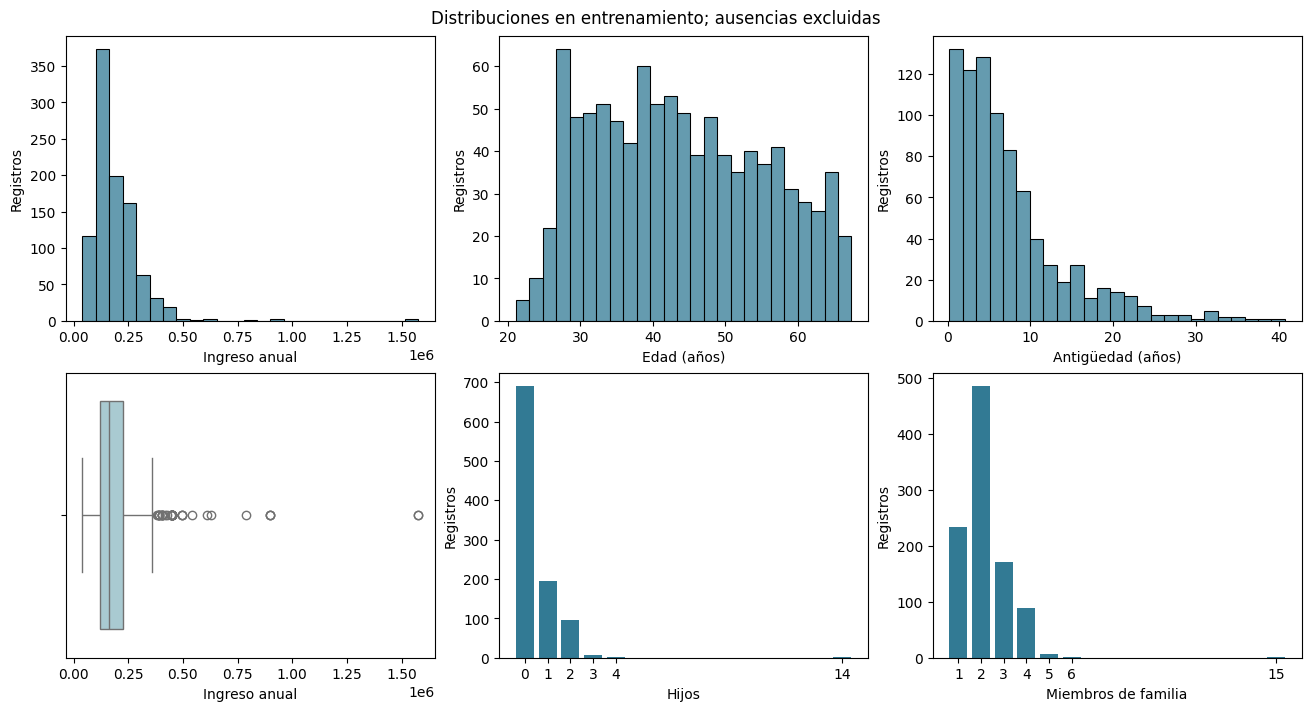

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
for ax, campo in zip(axes[0], ["Annual_income", "Edad_anios", "Antiguedad_anios"]):
    sns.histplot(cantidades[campo].dropna(), bins=25, ax=ax, color="#327a94")
    ax.set(xlabel=nombres[campo], ylabel="Registros")
sns.boxplot(x=cantidades["Annual_income"], ax=axes[1, 0], color="#a2ced8")
axes[1, 0].set(xlabel="Ingreso anual")
for ax, campo in zip(axes[1, 1:], ["CHILDREN", "Family_Members"]):
    frecuencia = cantidades[campo].value_counts().sort_index()
    ax.bar(frecuencia.index, frecuencia.values, color="#327a94")
    ax.set(xlabel=nombres[campo], ylabel="Registros", xticks=frecuencia.index)
fig.suptitle("Distribuciones en entrenamiento; ausencias excluidas")
plt.show()

In [16]:
q1, q3 = X_train["Annual_income"].quantile([0.25, 0.75])
limite_iqr = q3 + 1.5 * (q3 - q1)
p99_ingreso = X_train["Annual_income"].quantile(0.99)
display(pd.Series({
    "Límite exploratorio IQR": limite_iqr,
    "Registros por encima del IQR": X_train["Annual_income"].gt(limite_iqr).sum(),
    "Percentil 99 del ingreso (diagnóstico)": p99_ingreso,
    "Registros que limitaría el P99": X_train["Annual_income"].gt(p99_ingreso).sum(),
}, name="Valor").to_frame())
casos_extremos = X_train.nlargest(3, "Annual_income").index.union(
    X_train.nlargest(1, "CHILDREN").index, sort=False,
)
display(X_train.loc[casos_extremos, [
    "Annual_income", "Type_Income", "Type_Occupation", "CHILDREN", "Family_Members",
]].reset_index(drop=True))

,Valor
Límite exploratorio IQR,380250.0
Registros por encima del IQR,42.0
Percentil 99 del ingreso (diagnóstico),495000.0
Registros que limitaría el P99,9.0


,Annual_income,Type_Income,Type_Occupation,CHILDREN,Family_Members
0,1575000.0,Commercial associate,Managers,1,2
1,1575000.0,Commercial associate,Managers,1,2
2,900000.0,Commercial associate,Managers,2,4
3,225000.0,Working,Drivers,14,15


Hay **42 ingresos por encima de 380.250**, incluidos dos de **1.575.000**, y un registro con **14 hijos y 15 miembros de familia**. Su rareza no confirma un error: mantenemos las filas y sus valores como referencia inicial.

Un límite en el **P99 (495.000)** afectaría a **9 ingresos**, no solo a los dos máximos. Lo reservamos para una comparación posterior, aprendiendo el percentil dentro de cada entrenamiento. No aplicamos ahora recortes ni topes arbitrarios a hijos o familia.

Comparamos ahora las cantidades con la etiqueta y entre sí. Para visualizar el ingreso por clase usamos un eje logarítmico; esto no transforma la entrada del modelo.

,Ingreso anual,Edad (años),Antigüedad (años)
label,,,
Aprobación,166500.0,42.09,5.68
Rechazo,157500.0,47.27,3.90


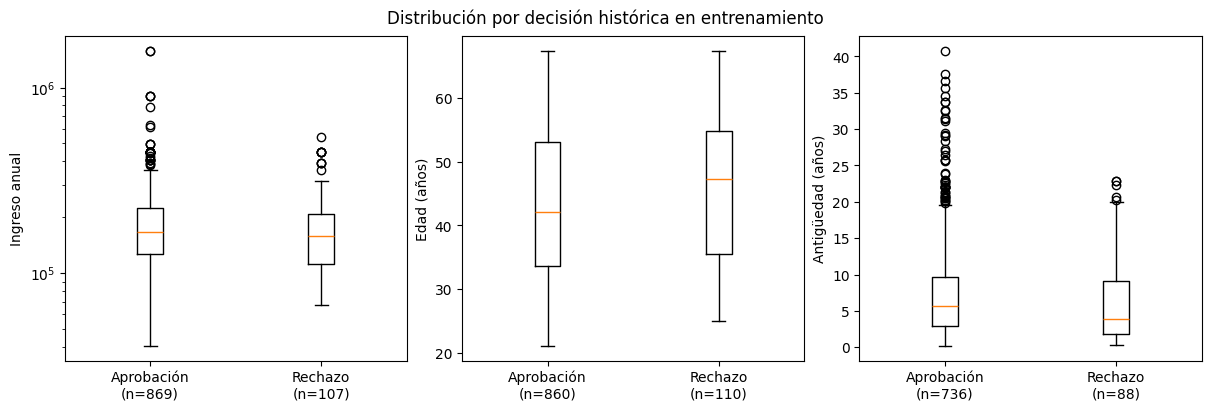

In [17]:
campos_clase = ["Annual_income", "Edad_anios", "Antiguedad_anios"]
display(cantidades[campos_clase].groupby(y_train).median().rename(
    index={0: "Aprobación", 1: "Rechazo"}, columns=nombres,
).round(2))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, campo in zip(axes, campos_clase):
    muestras = [cantidades.loc[y_train.eq(clase), campo].dropna() for clase in [0, 1]]
    etiquetas = [f"{clase}\n(n={len(muestra)})"
                 for clase, muestra in zip(["Aprobación", "Rechazo"], muestras)]
    ax.boxplot(muestras, tick_labels=etiquetas)
    ax.set(ylabel=nombres[campo])
    if campo == "Annual_income":
        ax.set_yscale("log")
fig.suptitle("Distribución por decisión histórica en entrenamiento")
plt.show()

La línea central representa la **mediana**: la antigüedad es **5,68 años en aprobaciones y 3,90 en rechazos**, con solapamiento. La edad mediana es **42,09 y 47,27 años**, respectivamente. Estas diferencias no justifican pesos manuales ni prueban causalidad; interesa comprobar su aportación conjunta al modelo.

Cada caja abarca del percentil 25 al 75 de su grupo; más registros no implican una caja más alta. El `n` indica los valores disponibles en cada gráfico, excluidas las ausencias y las duraciones sin interpretar.

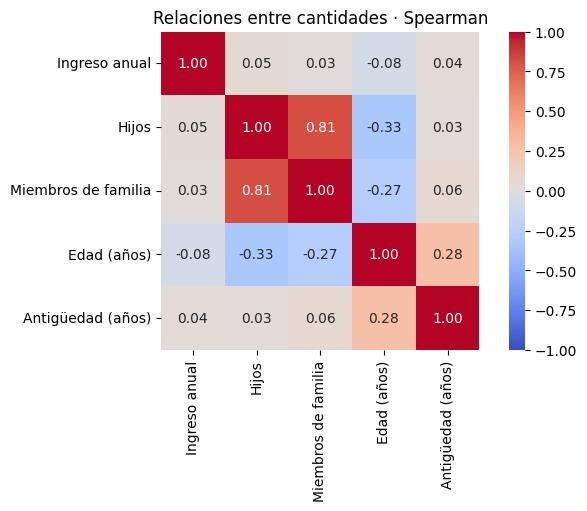

In [18]:
correlaciones = cantidades.rename(columns=nombres).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
sns.heatmap(correlaciones, annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap="coolwarm", square=True, ax=ax)
ax.set_title("Relaciones entre cantidades · Spearman")
plt.show()

Hijos y miembros de familia comparten información: **Spearman = 0,814**. La correlación no implica que sean intercambiables. Comprobamos qué diferencia queda entre ambos recuentos antes de proponer una reducción de entradas.

### Relación entre familia, hijos y estado civil

Calculamos `Family_Members − CHILDREN` y lo cruzamos con el estado civil, el ingreso y el rechazo. La diferencia describe los recuentos registrados; no acredita cuántos adultos conviven ni cuántas personas aportan ingresos.

In [19]:
composicion = X_train[["Family_Members", "CHILDREN", "Marital_status", "Annual_income"]].assign(
    Diferencia_familia_hijos=lambda tabla: tabla["Family_Members"] - tabla["CHILDREN"],
    label=y_train,
)
cruce_familiar = pd.crosstab(composicion["Marital_status"], composicion["Diferencia_familia_hijos"])
resumen_familiar = composicion.groupby("Diferencia_familia_hijos").agg(
    Registros=("label", "size"),
    Rechazos=("label", "sum"),
    Ingresos_informados=("Annual_income", "count"),
    Ingreso_mediano=("Annual_income", "median"),
)
resumen_familiar.insert(2, "Rechazo (%)", 100 * resumen_familiar["Rechazos"] / resumen_familiar["Registros"])
display(cruce_familiar, resumen_familiar.round(2))

Diferencia_familia_hijos,0,1,2
Marital_status,,,
Civil marriage,0,0,64
Married,1,0,647
Separated,0,65,0
Single / not married,1,155,10
Widow,0,47,0


,Registros,Rechazos,Rechazo (%),Ingresos_informados,Ingreso_mediano
Diferencia_familia_hijos,,,,,
0,2,2,100.00,2,303750.0
1,267,33,12.36,262,168750.0
2,721,77,10.68,712,162000.0


La diferencia vale **1 en 267 registros y 2 en 721**, con rechazo del **12,36 % y 10,68 %** e ingresos medianos de **168.750 y 162.000**. Está ligada al estado civil, pero no permite inferir ingresos totales del hogar ni un efecto del divorcio. Los **dos casos con diferencia 0** son las alertas familiares ya identificadas; ambos tienen rechazo, sin respaldo para generalizar desde dos observaciones.

Conservamos ambas cantidades y no añadimos la diferencia al modelo. Compararemos después una variante **sin `CHILDREN`**, manteniendo `Family_Members` y `Marital_status`; aún no hay evidencia de mejora predictiva.

### Categorías y agrupaciones con significado

Revisamos frecuencias y rechazo registrado, incluidos los indicadores binarios. Los gráficos se centran en las tres variables que agruparemos; el [resumen completo](../reports/resumen_categorias_entrenamiento.csv) conserva todos los niveles y sus recuentos.

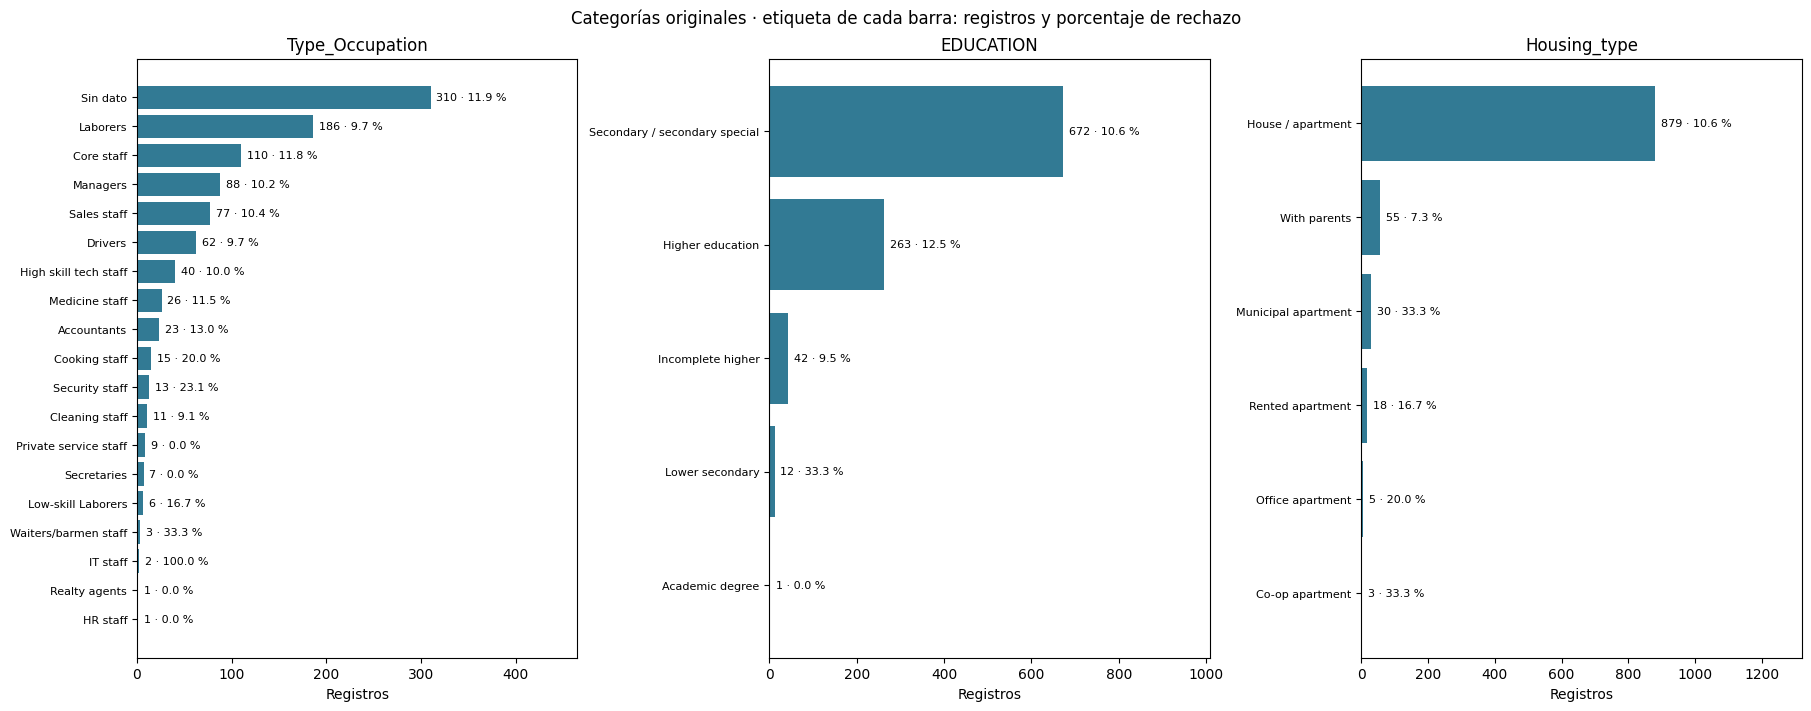

In [20]:
resumen_categorias = pd.concat({
    campo: y_train.groupby(X_train[campo], dropna=False).agg(Registros="size", Rechazos="sum")
    for campo in CATEGORICAS + ["Work_Phone", "Phone", "EMAIL_ID"]
}, names=["Variable", "Nivel"])
resumen_categorias["Rechazo (%)"] = 100 * resumen_categorias["Rechazos"] / resumen_categorias["Registros"]
REPORTS = RAIZ / "reports"
REPORTS.mkdir(exist_ok=True)
resumen_categorias.to_csv(REPORTS / "resumen_categorias_entrenamiento.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 7), layout="constrained")
for ax, campo in zip(axes, GRUPOS):
    tabla = resumen_categorias.loc[campo].sort_values("Registros")
    niveles = tabla.index.to_series().fillna("Sin dato").astype(str)
    ax.barh(niveles, tabla["Registros"], color="#327a94")
    for j, (_, fila) in enumerate(tabla.iterrows()):
        ax.text(fila["Registros"] + tabla["Registros"].max() * 0.02, j,
                f'{int(fila["Registros"])} · {fila["Rechazo (%)"]:.1f} %', va="center", fontsize=8)
    ax.set(xlabel="Registros", title=campo, xlim=(0, tabla["Registros"].max() * 1.5))
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Categorías originales · etiqueta de cada barra: registros y porcentaje de rechazo")
plt.show()

`IT staff` tiene **dos registros y dos rechazos**; esa tasa no permite concluir que toda la ocupación tenga el mismo comportamiento. Agruparemos por actividad y significado, sin utilizar las tasas para elegir qué categorías juntar.

In [21]:
correspondencias = pd.DataFrame([
    {"Variable": campo, "Grupo": grupo, "Categorías originales": ", ".join(niveles)}
    for campo, grupos in GRUPOS.items() for grupo, niveles in grupos.items()
])
with pd.option_context("display.max_colwidth", None):
    display(correspondencias)
correspondencias.to_csv(REPORTS / "agrupaciones_categoricas.csv", index=False)

,Variable,Grupo,Categorías originales
0,Type_Occupation,Administracion_y_gestion,"Accountants, HR staff, Managers, Secretaries"
1,Type_Occupation,Tecnicas_y_profesionales,"High skill tech staff, IT staff, Medicine staff"
2,Type_Occupation,Produccion_y_transporte,"Laborers, Low-skill Laborers, Drivers"
3,Type_Occupation,Ventas,"Sales staff, Realty agents"
4,Type_Occupation,Servicios_de_apoyo,"Cleaning staff, Cooking staff, Private service staff, Security staff, Waiters/barmen staff"
5,Type_Occupation,Personal_general,Core staff
6,EDUCATION,Superior_completa,"Academic degree, Higher education"
7,EDUCATION,Superior_incompleta,Incomplete higher
8,EDUCATION,Secundaria,"Lower secondary, Secondary / secondary special"
9,Housing_type,Casa_o_apartamento,House / apartment


En ocupación se usan familias amplias de actividad; `Core staff` queda separado por su significado impreciso. Educación distingue secundaria, superior incompleta y superior completa. Vivienda reúne las modalidades institucionales o colectivas, sin llamar alquiler a todas ellas ni atribuir propiedad a «casa o apartamento». La [justificación de las agrupaciones](../docs/Agrupaciones-categoricas.md) detalla los límites de esta simplificación.

In [22]:
vista_agrupada = agrupar_categorias(vista)
comparacion_niveles = pd.DataFrame({
    "Niveles originales (sin ausencias)": X_train[list(GRUPOS)].nunique(),
    "Grupos resultantes (sin ausencias)": [
        vista_agrupada.loc[X_train[campo].notna(), campo].nunique() for campo in GRUPOS
    ],
})
display(comparacion_niveles)
resumen_agrupado = pd.concat({
    campo: y_train.groupby(vista_agrupada[campo].fillna("__AUSENTE__")).agg(Registros="size", Rechazos="sum")
    for campo in GRUPOS
}, names=["Variable", "Grupo"])
resumen_agrupado["Rechazo (%)"] = 100 * resumen_agrupado["Rechazos"] / resumen_agrupado["Registros"]
display(resumen_agrupado.round(2))
resumen_agrupado.to_csv(REPORTS / "resumen_agrupaciones_entrenamiento.csv")

,Niveles originales (sin ausencias),Grupos resultantes (sin ausencias)
Type_Occupation,18,6
EDUCATION,5,3
Housing_type,6,4


Registros  Rechazos  Rechazo (%)
Variable        Grupo                                                      
Type_Occupation Administracion_y_gestion         119        12        10.08
                Personal_general                 110        13        11.82
                Produccion_y_transporte          254        25         9.84
                Servicios_de_apoyo                51         8        15.69
                Tecnicas_y_profesionales          68         9        13.24
                Ventas                            78         8        10.26
                __AUSENTE__                      310        37        11.94
EDUCATION       Secundaria                       684        75        10.96
                Superior_completa                264        33        12.50
                Superior_incompleta               42         4         9.52
Housing_type    Alquiler_declarado                18         3        16.67
                Casa_o_apartamento               879        93        10.58
                Con_familiares                    55         4         7.27
                Institucional_o_colectiva         38        12        31.58

Ocupación pasa de **18 niveles informados a 6 grupos**, educación de **5 a 3** y vivienda de **6 a 4**. Los grupos de ocupación tienen entre **51 y 254 registros**, además de la ausencia explícita. El alquiler conserva 18 casos y se mantiene separado por significado. Estas agrupaciones simplifican la representación; no se ha contrastado su ventaja predictiva frente a las categorías originales.


### Ausencias y decisiones de tratamiento

Comparamos los casos con y sin dato para justificar su representación. Los porcentajes se acompañan del tamaño de cada grupo; una diferencia con pocos registros solo plantea una hipótesis.

In [23]:
resumen_ausencias = pd.concat({
    campo: y_train.groupby(X_train[campo].isna().map({False: "Informado", True: "Ausente"})).agg(
        Registros="size", Rechazos="sum",
    )
    for campo in X_train.columns[X_train.isna().any()]
}, names=["Variable", "Estado"])
resumen_ausencias["Rechazo (%)"] = 100 * resumen_ausencias["Rechazos"] / resumen_ausencias["Registros"]
display(resumen_ausencias.round(2))

Registros  Rechazos  Rechazo (%)
Variable        Estado                                     
GENDER          Ausente            6         5        83.33
                Informado        984       107        10.87
Annual_income   Ausente           14         5        35.71
                Informado        976       107        10.96
Birthday_count  Ausente           20         2        10.00
                Informado        970       110        11.34
Type_Occupation Ausente          310        37        11.94
                Informado        680        75        11.03

Falta ingreso en **14 registros**, con **5 rechazos (35,71 %)**. Incluimos un indicador de ausencia como hipótesis de representación, sin haber aislado su aportación predictiva. De las **310 ocupaciones ausentes**, 166 acompañan al código positivo de empleo y 144 no; su indicador mantiene distinguibles ambos contextos.


| Entrada | Preparación inicial y motivo |
|---|---|
| Ingreso y edad ausentes | Mediana aprendida en entrenamiento; el ingreso asimétrico aconseja una referencia resistente a sus extremos. No se supone que un ingreso desconocido sea bajo o cero. |
| Código especial de empleo | Indicador propio y duración de soporte igual a cero; no representa una antigüedad observada ni experiencia laboral total. |
| Categorías ausentes | `__AUSENTE__`, sin atribuir género u ocupación desconocidos a la categoría mayoritaria. |
| Ingreso ausente | Indicador calculado antes de imputar. |
| Extremos y familia | Conservar filas y ambas cantidades en la referencia inicial. Contrastar después combinaciones de P99 de ingreso y familia, exclusión de `CHILDREN` y logaritmo del ingreso. |


### Preparación reutilizable

Unimos las reglas fijas con imputación y codificación. Ajustamos una vista de diagnóstico solo con entrenamiento; al comparar modelos, el pipeline completo se reajusta en cada fold. Las cantidades se escalan para logística y se conservan sin escalar para los árboles.


In [24]:
numericas = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])
columnas = ColumnTransformer([
    ("num", numericas, NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ("bin", "passthrough", BINARIAS),
], verbose_feature_names_out=False).set_output(transform="pandas")
preparacion = Pipeline([
    ("representar", FunctionTransformer(representar_variables)),
    ("reglas", FunctionTransformer(aplicar_reglas)),
    ("columnas", columnas),
])
Z_train = preparacion.fit_transform(X_train)
assert Z_train.index.equals(X_train.index) and np.isfinite(Z_train.to_numpy()).all()
print(f"Preparación ajustada: {Z_train.shape[0]} filas y {Z_train.shape[1]} columnas numéricas.")

Preparación ajustada: 990 filas y 40 columnas numéricas.


### Comprobación de la preparación

Revisamos qué valores aprendió el imputador y dónde se aplicaron, antes del escalado. Los ceros de duración asociados al código especial son una regla fija diferenciada por su indicador, no medianas aprendidas.


In [25]:
vista_reglas = aplicar_reglas(vista)
imputador = preparacion.named_steps["columnas"].named_transformers_["num"].named_steps["imputar"]
numericas_imputadas = pd.DataFrame(
    imputador.transform(vista_reglas[NUMERICAS]), index=X_train.index, columns=NUMERICAS,
)
resumen_imputacion = pd.DataFrame({
    "Ausencias antes del imputador": vista_reglas[NUMERICAS].isna().sum(),
    "Mediana aprendida": imputador.statistics_,
    "Ausencias después": numericas_imputadas.isna().sum(),
})
display(resumen_imputacion.round(3))
resumen_imputacion.to_csv(REPORTS / "imputacion_entrenamiento.csv")
vista_preparada = vista_reglas.copy()
vista_preparada[NUMERICAS] = numericas_imputadas
display(vista_preparada[["Edad_anios", "Antiguedad_anios", "Codigo_empleo_positivo",
                     "Ingreso_ausente", "Type_Occupation", "EDUCATION", "Housing_type"]].head().reset_index(drop=True))

,Ausencias antes del imputador,Mediana aprendida,Ausencias después
Annual_income,14,162000.000,0
CHILDREN,0,0.000,0
Family_Members,0,2.000,0
Edad_anios,20,42.337,0
Antiguedad_anios,0,4.359,0


,Edad_anios,Antiguedad_anios,Codigo_empleo_positivo,Ingreso_ausente,Type_Occupation,EDUCATION,Housing_type
0,46.965092,4.514716,0,0,Produccion_y_transporte,Secundaria,Casa_o_apartamento
1,33.333333,4.005476,0,0,Personal_general,Secundaria,Casa_o_apartamento
2,28.320329,6.934976,0,0,Produccion_y_transporte,Secundaria,Casa_o_apartamento
3,38.559890,7.381246,0,0,Produccion_y_transporte,Secundaria,Institucional_o_colectiva
4,26.266940,2.370979,0,0,Produccion_y_transporte,Secundaria,Casa_o_apartamento


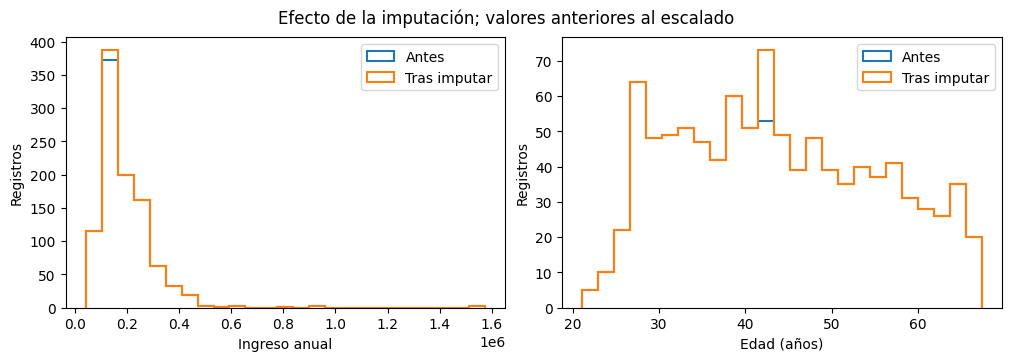

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for ax, campo in zip(axes, ["Annual_income", "Edad_anios"]):
    bins = np.histogram_bin_edges(numericas_imputadas[campo], bins=25)
    ax.hist(vista_reglas[campo].dropna(), bins=bins, histtype="step", linewidth=1.5, label="Antes")
    ax.hist(numericas_imputadas[campo], bins=bins, histtype="step", linewidth=1.5, label="Tras imputar")
    ax.set(xlabel=nombres[campo], ylabel="Registros")
    ax.legend()
fig.suptitle("Efecto de la imputación; valores anteriores al escalado")
plt.show()

Se imputan **14 ingresos y 20 edades**; los valores informados permanecen intactos antes de escalar. La preparación produce **40 columnas** y conserva las 990 filas. Una categoría futura no reconocida se codificará con ceros en su bloque; comprobamos ese comportamiento con un ejemplo sintético, sin consultar validación ni test.

In [27]:
prueba = X_train.iloc[[0]].copy()
prueba["Type_Occupation"] = "Ocupacion_nueva"
prueba["Annual_income"] = np.nan
estadisticas_antes = imputador.statistics_.copy()
Z_prueba = preparacion.transform(prueba)

assert Z_prueba.columns.equals(Z_train.columns) and np.isfinite(Z_prueba.to_numpy()).all()
assert Z_prueba.filter(like="Type_Occupation_").eq(0).all().all()
assert Z_prueba["Ingreso_ausente"].eq(1).all()
np.testing.assert_array_equal(imputador.statistics_, estadisticas_antes)
print("Ejemplo sintético aceptado: categoría nueva, ingreso ausente y estadísticas sin reajuste.")

Ejemplo sintético aceptado: categoría nueva, ingreso ausente y estadísticas sin reajuste.


La preparación inicial queda definida: años e indicadores interpretables, agrupaciones semánticas, ausencias explícitas y medianas aprendidas en entrenamiento. Se conservan las 990 filas, los extremos y ambas cantidades familiares. La diferencia familia–hijos se ha explorado, pero no se añade al pipeline.

El siguiente bloque compara modelos con esta preparación, reajustada en cada fold. Después se contrastan recortes de extremos, exclusión de hijos y logaritmo del ingreso. Las agrupaciones son una elección de representación; no se ha demostrado que superen las categorías originales.


## 4. Comparación inicial de modelos

Comparamos tres modelos en los **1.238 registros de desarrollo**, con los cinco folds ya fijados. La clase positiva es el rechazo registrado y el umbral inicial es **0,5**; el criterio principal será el F1 medio entre folds.

Mantenemos la preparación revisada, los extremos y ambas cantidades familiares. El test queda reservado; esta comparación sigue siendo una evaluación interna sobre datos públicos ya examinados.


### Modelos candidatos

Los tres modelos usan **`class_weight="balanced"`**: cada entrenamiento da mayor peso a los rechazos minoritarios. No se duplican filas ni se ponderan las métricas.

| Modelo | Configuración inicial |
|---|---|
| Logística | L2, C=1, máximo 2.000 iteraciones y escalado numérico. |
| Árbol | Profundidad máxima 5 para limitar su crecimiento. |
| Random Forest | 100 árboles, sin límite fijo de profundidad. |

Los parámetros restantes conservan sus valores predeterminados. Estas configuraciones son el punto de partida, sin optimización todavía.


In [28]:
estimadores = {
    "Logística": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Árbol": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1),
}
preparacion_arboles = clone(preparacion).set_params(columnas__num__escalar="passthrough")
candidatos = {}
for nombre, estimador in estimadores.items():
    base = preparacion if nombre == "Logística" else preparacion_arboles
    candidatos[nombre] = Pipeline([
        ("preparar", clone(base)),
        ("modelo", estimador),
    ])


### Entrenamiento y tabla comparativa

Entrenamos cada candidato en los cinco folds y mostramos sus métricas medias de validación, en porcentaje. La [rutina común](../src/evaluacion.py) reajusta la preparación solo con el entrenamiento de cada fold; el test permanece reservado.

In [29]:
UMBRAL = configuracion["umbral_inicial"]
por_fold, predicciones_cv = evaluar_candidatos(candidatos, X_dev, y_dev, particiones, UMBRAL)
cobertura = predicciones_cv.groupby("Modelo", sort=False).agg(
    Registros=("Ind_ID", "size"), Identificadores=("Ind_ID", "nunique"), Folds=("Fold", "nunique"),
)
assert cobertura["Registros"].eq(len(X_dev)).all()
assert cobertura["Identificadores"].eq(len(X_dev)).all() and cobertura["Folds"].eq(5).all()
print(f"{len(por_fold)} ajustes: {len(candidatos)} candidatos × {len(particiones)} folds; "
      f"{len(X_dev)} predicciones de validación por candidato.")

comparacion = por_fold.groupby("Modelo", sort=False).agg(
    F1=("F1", "mean"), F1_std=("F1", "std"),
    Precision=("Precision", "mean"), Recall=("Recall", "mean"),
    ROC_AUC=("ROC_AUC", "mean"), Accuracy=("Accuracy", "mean"),
    F1_train=("F1_train", "mean"),
).sort_values("F1", ascending=False)

metricas_tabla = ["F1", "Precision", "Recall", "ROC_AUC", "Accuracy"]
nombres_metricas = {
    "F1": "F1 validación (%)", "Precision": "Precisión (%)", "Recall": "Recall (%)",
    "ROC_AUC": "ROC-AUC (%)", "Accuracy": "Accuracy (%)",
}
print("Comparación de modelos · medias de cinco folds · umbral 0,5")
display((100 * comparacion.loc[list(estimadores), metricas_tabla])
        .rename(columns=nombres_metricas).round(2))


15 ajustes: 3 candidatos × 5 folds; 1238 predicciones de validación por candidato.
Comparación de modelos · medias de cinco folds · umbral 0,5


,F1 validación (%),Precisión (%),Recall (%),ROC-AUC (%),Accuracy (%)
Modelo,,,,,
Logística,24.20,15.90,50.71,61.20,64.30
Árbol,25.59,17.48,55.71,60.84,60.64
Random Forest,52.04,63.00,45.00,74.27,90.71


El bosque destaca en F1, precisión, ROC-AUC y accuracy. Árbol y logística detectan más rechazos, pero con menor precisión. Para orientar la optimización, revisamos ahora la brecha de F1, la variación entre folds y los tipos de error.

### Entrenamiento frente a validación

Comparamos el F1 sobre los datos utilizados para aprender con el obtenido al validar. Una caída grande ayuda a identificar si conviene controlar la complejidad del modelo.


In [30]:
display((100 * comparacion.loc[list(estimadores), ["F1_train", "F1"]])
        .rename(columns={"F1_train": "F1 entrenamiento (%)", "F1": "F1 validación (%)"})
        .round(2))


,F1 entrenamiento (%),F1 validación (%)
Modelo,,
Logística,29.66,24.20
Árbol,34.41,25.59
Random Forest,97.06,52.04


El F1 del bosque baja de **97,06 % en entrenamiento a 52,04 % en validación**: parte de lo aprendido no se mantiene fuera del entrenamiento. Esto orienta a probar límites de complejidad, sin garantizar que mejoren el resultado.

### Variación entre particiones

Mostramos el F1 en cada fold para ver cuánto depende de la muestra de validación. Son **cinco particiones distintas, no etapas de aprendizaje**; las líneas solo facilitan comparar los modelos.


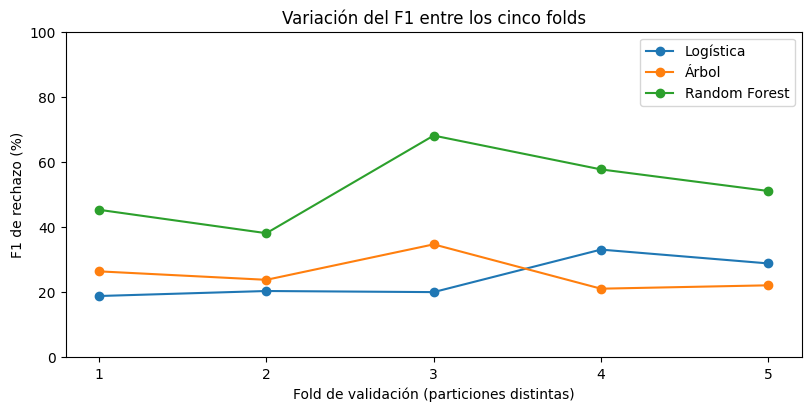

In [31]:
f1_folds = por_fold.pivot(index="Fold", columns="Modelo", values="F1")
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for nombre in estimadores:
    ax.plot(f1_folds.index, 100 * f1_folds[nombre], marker="o", label=nombre)
ax.set(xlabel="Fold de validación (particiones distintas)", ylabel="F1 de rechazo (%)",
       xticks=f1_folds.index, ylim=(0, 100), title="Variación del F1 entre los cinco folds")
ax.legend()
plt.show()


El bosque obtiene entre **38,10 % y 68,09 % de F1** según la partición. Su media de 52,04 % resume resultados variables: al optimizarlo compararemos los mismos cinco folds, sin elegir solo el más favorable.


### Matrices de confusión y errores

Revisamos qué errores explican las métricas: filas = decisión registrada; columnas = predicción. Un falso positivo es una aprobación clasificada como rechazo; un falso negativo, un rechazo clasificado como aprobación. Cada cliente se evalúa fuera de su entrenamiento.


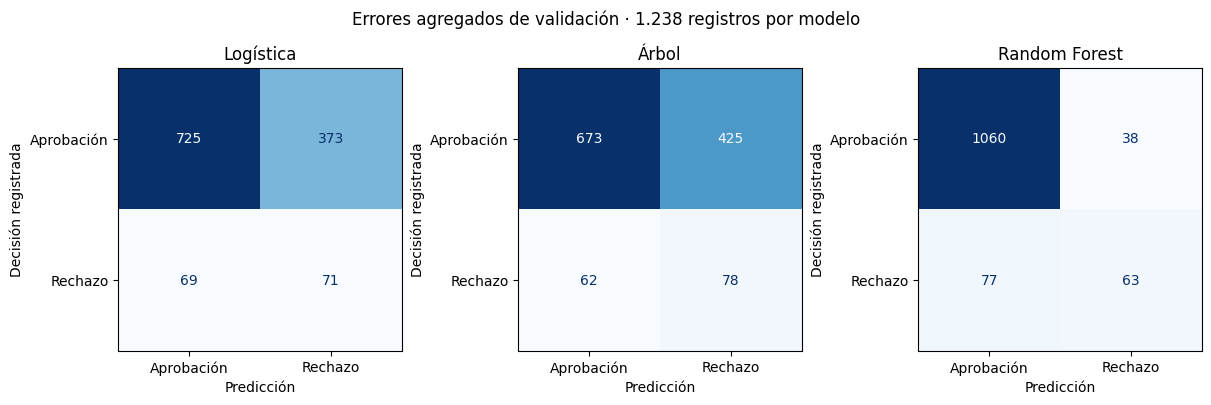

In [32]:
recuentos_errores = pd.DataFrame({
    nombre: confusion_matrix(
        grupo["Real"], grupo["Prediccion"], labels=[0, 1],
    ).ravel()
    for nombre, grupo in predicciones_cv.groupby("Modelo", sort=False)
}, index=["TN", "FP", "FN", "TP"]).T.rename_axis("Modelo")
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, nombre in zip(axes, estimadores):
    matriz = recuentos_errores.loc[nombre].to_numpy().reshape(2, 2)
    ConfusionMatrixDisplay(matriz, display_labels=["Aprobación", "Rechazo"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
    )
    ax.set(title=nombre, xlabel="Predicción", ylabel="Decisión registrada")
fig.suptitle("Errores agregados de validación · 1.238 registros por modelo")
plt.show()


De los **140 rechazos**, el bosque detecta **63**, deja **77** sin detectar y genera **38 falsos positivos**. Árbol y logística detectan más (78 y 71), pero generan muchas más falsas alertas (425 y 373).

Son errores sobre decisiones registradas, no impagos. Las métricas de estas matrices agregadas pueden diferir de las medias por fold.


### Elección provisional

Elegimos **Random Forest** por su mayor F1 medio. Ningún otro modelo queda a menos de un punto porcentual, por lo que la preferencia acordada por modelos más sencillos no cambia la elección. Será la referencia para optimizar sus hiperparámetros con los mismos folds.


In [33]:
nombre_provisional = "Random Forest"
candidato_provisional = clone(candidatos[nombre_provisional])


### Registro de la comparación

Guardamos métricas, errores y parámetros para comparar las próximas pruebas con este punto de partida. Se conserva la configuración del bosque, sin reajustarlo todavía con todo desarrollo.


In [34]:
por_fold.to_csv(REPORTS / "modelos_iniciales_por_fold.csv", index=False)
comparacion.to_csv(REPORTS / "comparacion_inicial.csv")
recuentos_errores.to_csv(REPORTS / "errores_validacion_inicial.csv")
# Archivo local con identificadores, excluido de Git.
predicciones_cv.to_csv(REPORTS / "predicciones_cv_inicial.csv", index=False)
registro_inicial = {
    "evaluacion": "../evaluacion/configuracion.json",
    "muestra": "desarrollo", "umbral": UMBRAL,
    "preparacion": "sección 3; sin recorte ni selección familiar; escalado solo para logística",
    "parametros": {
        nombre: plantilla.named_steps["modelo"].get_params(deep=False)
        for nombre, plantilla in candidatos.items()
    },
    "candidato_provisional": nombre_provisional,
    "reajuste_final": False, "test_evaluado": False,
}
(REPORTS / "configuracion_modelos_iniciales.json").write_text(
    json.dumps(registro_inicial, ensure_ascii=False, indent=2) + "\n", encoding="utf-8",
)
print("Comparación, configuración y errores guardados; predicciones individuales solo en local.")


Comparación, configuración y errores guardados; predicciones individuales solo en local.


Los [informes](../reports/README.md) conservan los resultados agregados; las predicciones individuales quedan solo en local. Antes de optimizar el bosque contrastamos unas pocas alternativas de preparación en la sección siguiente. El test sigue reservado.


## 5. Contrastes de preparación

Contrastamos cuatro combinaciones para limitar extremos, reducir redundancia familiar y representar mejor la escala del ingreso. Comparamos **logística y Random Forest** con sus preparaciones actuales, sin cambiar parámetros, folds ni umbral.

| Variante | Cambio frente a la preparación actual |
|---|---|
| P99 ingreso y familia | Limitar ambas variables al P99 aprendido en cada entrenamiento. |
| P99 sin hijos | Aplicar esos dos límites y excluir `CHILDREN`. |
| Log ingreso | Sustituir el ingreso por `log(1 + ingreso)`, conservando las demás entradas. |
| P99 + log sin hijos | Aplicar ambos límites, transformar después el ingreso y excluir `CHILDREN`. |

La comparación entre las dos primeras aísla la exclusión de hijos; entre la segunda y la cuarta, el logaritmo tras recortar. La variante con solo logaritmo comprueba su efecto sin recortes. Reutilizamos las referencias iniciales: son **ocho candidatos nuevos**, no todas las combinaciones posibles. Si la mejora no alcanza **un punto porcentual de F1**, conservaremos la preparación actual.


In [35]:
familias_prueba = ["Logística", "Random Forest"]
tratamientos = {
    "P99 ingreso y familia": {"p99": True, "sin_hijos": False, "log_ingreso": False},
    "P99 sin hijos": {"p99": True, "sin_hijos": True, "log_ingreso": False},
    "Log ingreso": {"p99": False, "sin_hijos": False, "log_ingreso": True},
    "P99 + log sin hijos": {"p99": True, "sin_hijos": True, "log_ingreso": True},
}
alternativas, fichas_variantes = {}, []
for familia in familias_prueba:
    for variante, opciones in tratamientos.items():
        modelo = clone(candidatos[familia])
        preparar = modelo.named_steps["preparar"]
        pasos_extra = []
        if opciones["p99"]:
            pasos_extra.append(("limitar_extremos", LimitarExtremos(cuantil=0.99)))
        if opciones["log_ingreso"]:
            pasos_extra.append(("log_ingreso", FunctionTransformer(transformar_ingreso_log)))
        preparar.steps = pasos_extra + preparar.steps
        if opciones["sin_hijos"]:
            columnas_variante = preparar.named_steps["columnas"]
            columnas_variante.transformers = [
                (nombre, transformador, [c for c in campos if c != "CHILDREN"])
                for nombre, transformador, campos in columnas_variante.transformers
            ]
        nombre = f"{familia} · {variante}"
        alternativas[nombre] = modelo
        fichas_variantes.append({"Candidato": nombre, "Familia": familia, "Variante": variante})


### Comparación de las preparaciones

Los [recortes](../src/preparacion.py) se aprenden en cada entrenamiento y se aplican sobre copias, también en validación. Familia usa un percentil discreto: el límite es **4 en el primer entrenamiento**, no necesariamente en los demás. Estos valores son entradas limitadas para el modelo, no correcciones de las familias registradas.

El logaritmo comprime la escala del ingreso; puede facilitar relaciones a la logística, sin garantizar una mejora. Se aplica tras el recorte cuando se combinan. Ausencias, imputación y escalado siguen dentro del pipeline; los archivos originales permanecen intactos.


In [36]:
folds_nuevos, predicciones_variantes = evaluar_candidatos(
    alternativas, X_dev, y_dev, particiones, UMBRAL,
)
fichas = pd.DataFrame(fichas_variantes).set_index("Candidato")
detalle_variantes = folds_nuevos.join(fichas, on="Modelo")
iniciales = por_fold.loc[por_fold["Modelo"].isin(familias_prueba)].copy()
iniciales = iniciales.assign(Familia=iniciales["Modelo"], Variante="Actual")
folds_preparaciones = pd.concat([iniciales, detalle_variantes], ignore_index=True)
orden = pd.MultiIndex.from_product(
    [familias_prueba, ["Actual", *tratamientos]], names=["Familia", "Variante"],
)
resumen_preparaciones = folds_preparaciones.groupby(["Familia", "Variante"]).agg(
    F1=("F1", "mean"), F1_std=("F1", "std"), F1_train=("F1_train", "mean"),
    Precision=("Precision", "mean"), Recall=("Recall", "mean"),
    ROC_AUC=("ROC_AUC", "mean"), Accuracy=("Accuracy", "mean"),
).reindex(orden)
resumen_preparaciones["Delta_F1"] = (
    resumen_preparaciones["F1"]
    - resumen_preparaciones.index.get_level_values("Familia").map(comparacion["F1"])
)
print("40 ajustes nuevos · ocho candidatos × cinco folds · test reservado")
display((100 * resumen_preparaciones[metricas_tabla + ["Delta_F1"]])
        .rename(columns={**nombres_metricas, "Delta_F1": "Cambio F1 (puntos)"}).round(2))


40 ajustes nuevos · ocho candidatos × cinco folds · test reservado


F1 validación (%)  Precisión (%)  \
Familia       Variante                                                  
Logística     Actual                             24.20          15.90   
              P99 ingreso y familia              24.88          16.34   
              P99 sin hijos                      24.55          16.13   
              Log ingreso                        23.72          15.55   
              P99 + log sin hijos                22.95          15.03   
Random Forest Actual                             52.04          63.00   
              P99 ingreso y familia              51.09          61.57   
              P99 sin hijos                      49.97          57.64   
              Log ingreso                        52.34          63.94   
              P99 + log sin hijos                50.51          58.65   

                                     Recall (%)  ROC-AUC (%)  Accuracy (%)  \
Familia       Variante                                                       
Logística     Actual                      50.71        61.20         64.30   
              P99 ingreso y familia       52.14        61.04         64.46   
              P99 sin hijos               51.43        61.33         64.30   
              Log ingreso                 50.00        60.81         63.66   
              P99 + log sin hijos         48.57        61.10         63.25   
Random Forest Actual                      45.00        74.27         90.71   
              P99 ingreso y familia       44.29        74.36         90.55   
              P99 sin hijos               45.00        74.92         89.90   
              Log ingreso                 45.00        74.16         90.79   
              P99 + log sin hijos         45.00        74.89         90.07   

                                     Cambio F1 (puntos)  
Familia       Variante                                   
Logística     Actual                               0.00  
              P99 ingreso y familia                0.68  
              P99 sin hijos                        0.35  
              Log ingreso                         -0.48  
              P99 + log sin hijos                 -1.25  
Random Forest Actual                               0.00  
              P99 ingreso y familia               -0.95  
              P99 sin hijos                       -2.07  
              Log ingreso                          0.30  
              P99 + log sin hijos                 -1.54

El recorte conjunto mejora ligeramente la logística: **F1 24,20 % → 24,88 %** y recall 50,71 % → 52,14 %. En el bosque, el mejor contraste es **Log ingreso: F1 52,04 % → 52,34 %**, con el mismo recall (45,00 %); recortar o añadir la exclusión de hijos empeora su F1.

Ninguna ganancia alcanza el punto porcentual fijado para cambiar la preparación. La combinación de los cuatro tratamientos tampoco mejora la referencia: añadir cambios no garantiza un mejor modelo.


### Cambios de F1 entre particiones

Restamos, fold a fold, el F1 de la preparación actual al de cada variante. Una barra positiva indica mejora; una negativa, empeoramiento sobre los mismos clientes de validación. Así distinguimos un cambio repartido de otro concentrado en una sola partición.


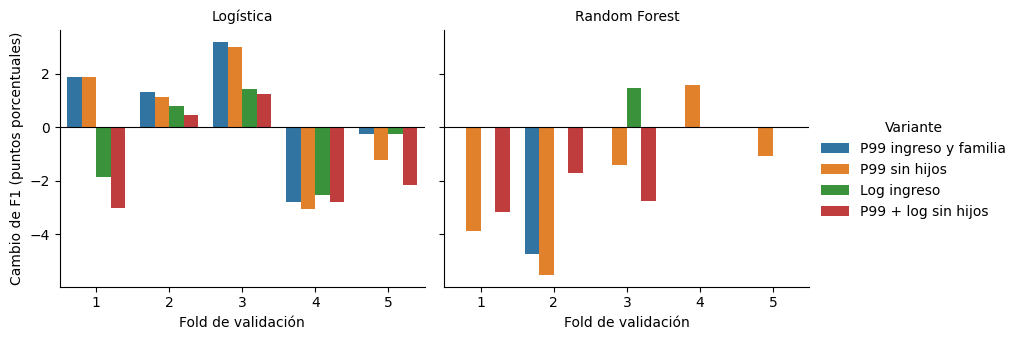

In [37]:
referencia_folds = iniciales[["Familia", "Fold", "F1"]].rename(columns={"F1": "F1_actual"})
diferencias_preparacion = detalle_variantes.merge(
    referencia_folds, on=["Familia", "Fold"], validate="many_to_one",
)
diferencias_preparacion["Cambio_F1"] = (
    100 * (diferencias_preparacion["F1"] - diferencias_preparacion["F1_actual"])
)
grafico = sns.catplot(
    data=diferencias_preparacion, kind="bar", x="Fold", y="Cambio_F1",
    hue="Variante", hue_order=list(tratamientos), col="Familia", col_order=familias_prueba,
    errorbar=None, height=3.5, aspect=1.2,
)
grafico.set_axis_labels("Fold de validación", "Cambio de F1 (puntos porcentuales)")
grafico.set_titles("{col_name}")
for ax in grafico.axes.flat:
    ax.axhline(0, color="black", linewidth=0.8)
plt.show()


El recorte conjunto mejora la logística en tres folds y empeora en dos. En el bosque, el logaritmo solo mejora el tercer fold (+1,48 puntos de F1) y empata en los otros cuatro: su pequeña ganancia media no se repite entre particiones. Las variantes con recorte tampoco muestran una ventaja sostenida.


### Preparación elegida para continuar

Conservamos la **preparación actual en ambos modelos**. Las pequeñas mejoras no alcanzan la regla acordada y no son uniformes entre folds. El bosque mantiene ingreso sin transformar y ambas cantidades familiares; esta elección corresponde a los parámetros comparados, no descarta cualquier mejora futura de preparación.


In [38]:
preparaciones_elegidas = {"Random Forest": "Actual", "Logística": "Actual"}
modelos_preparados = {
    familia: clone(candidatos[familia] if variante == "Actual"
                   else alternativas[f"{familia} · {variante}"])
    for familia, variante in preparaciones_elegidas.items()
}


### Registro del contraste

Guardamos las variantes y sus resultados para conservar la comparación. Las predicciones individuales se mantienen solo en local; la elección guarda configuraciones, no modelos entrenados para entregar.


In [39]:
folds_preparaciones.to_csv(REPORTS / "preparaciones_por_fold.csv", index=False)
resumen_preparaciones.to_csv(REPORTS / "comparacion_preparaciones.csv")
diferencias_preparacion.to_csv(REPORTS / "diferencias_preparaciones_por_fold.csv", index=False)
predicciones_variantes.to_csv(REPORTS / "predicciones_cv_variantes.csv", index=False)
registro_preparaciones = {
    "evaluacion": "../evaluacion/configuracion.json", "umbral": UMBRAL,
    "parametros_modelos": "configuracion_modelos_iniciales.json",
    "variantes": tratamientos,
    "recorte": {
        "cuantil": 0.99, "columnas": ["Annual_income", "Family_Members"],
        "interpolacion": {"Annual_income": "linear", "Family_Members": "higher"},
        "ajuste": "Solo entrenamiento de cada fold",
    },
    "log_ingreso": "log1p(Annual_income), después del recorte cuando se combinan",
    "orden": ["recorte opcional", "logaritmo opcional", "representación y reglas",
              "selección de entradas, imputación y codificación/escalado", "modelo"],
    "criterio": "Conservar actual si la mejora de F1 es menor de 0,01; revisar diferencias por fold",
    "preparaciones_elegidas": preparaciones_elegidas,
    "grid_search_ejecutado": False, "test_evaluado": False,
}
(REPORTS / "configuracion_preparaciones.json").write_text(
    json.dumps(registro_preparaciones, ensure_ascii=False, indent=2) + "\n", encoding="utf-8",
)
print("Resultados del contraste y preparaciones elegidas guardados.")


Resultados del contraste y preparaciones elegidas guardados.


Continuamos con Random Forest y su preparación actual: **F1 52,04 %, recall 45,00 % y AUC 74,27 %**. Logística permanece como comparación. A continuación buscamos hiperparámetros con los mismos folds, manteniendo el test reservado.


## 6. Optimización y evaluación final

Ajustamos la capacidad de Random Forest con la preparación elegida. La búsqueda utiliza los mismos cinco folds de desarrollo y F1 como criterio; el test sigue reservado. Primero comparamos el bosque ajustado con los tres modelos iniciales y fijamos una propuesta para el cierre.


### Búsqueda acotada de hiperparámetros

La brecha entre entrenamiento y validación aconseja contrastar árboles más contenidos, sin descartar los flexibles. Probamos también la ponderación: el desbalance no garantiza que `balanced` sea siempre la mejor opción.

| Parámetro | Valores | Qué permite comprobar |
|---|---|---|
| Profundidad máxima | 5, 10 y sin límite | Capacidad para representar relaciones complejas. |
| Mínimo de observaciones por hoja | 1, 3 y 5 | Evitar hojas basadas en muy pocos ejemplos. |
| Variables por división | Raíz cuadrada y 50 % | Diversidad entre árboles frente a información disponible en cada corte. |
| Pesos de clase | `balanced` y sin ponderar | Detección de rechazos y falsas alertas. |

Son **36 configuraciones × 5 folds = 180 ajustes**, incluida la configuración inicial. Conservamos 100 árboles, semilla 42 y umbral 0,5; la igualdad con el umbral se clasifica como rechazo en toda la comparación.


In [40]:
rejilla_bosque = {
    "modelo__max_depth": [5, 10, None],
    "modelo__min_samples_leaf": [1, 3, 5],
    "modelo__max_features": ["sqrt", 0.5],
    "modelo__class_weight": ["balanced", None],
}
bosque_base = clone(modelos_preparados["Random Forest"])
scorer_f1 = partial(puntuar_f1, umbral=UMBRAL)
busqueda = GridSearchCV(
    bosque_base, rejilla_bosque, scoring=scorer_f1, cv=particiones,
    refit=False, return_train_score=True, n_jobs=1, error_score="raise",
)
busqueda.fit(X_dev, y_dev)
print(f"{len(list(ParameterGrid(rejilla_bosque)))} configuraciones × {len(particiones)} folds. "
      "Búsqueda terminada; sin reajuste final ni evaluación de test.")


36 configuraciones × 5 folds. Búsqueda terminada; sin reajuste final ni evaluación de test.


### Resultados de la búsqueda

Mostramos las cinco configuraciones con mayor F1 y la elegida si no figura entre ellas. Aplicamos la regla fijada: entre opciones a no más de un punto porcentual de F1 del máximo, preferimos menor dispersión y después mayor F1. Estos resultados sirven para seleccionar; no constituyen otra evaluación independiente.


In [41]:
resultados_busqueda = pd.DataFrame(busqueda.cv_results_)
columnas_fold = [f"split{i}_test_score" for i in range(len(particiones))]
resultados_busqueda["Desv_F1"] = resultados_busqueda[columnas_fold].std(axis=1, ddof=1)
maximo_f1 = resultados_busqueda["mean_test_score"].max()
cercanos = resultados_busqueda.loc[
    resultados_busqueda["mean_test_score"].ge(maximo_f1 - configuracion["tolerancia_simplicidad_f1"])
]
indice_elegido = cercanos.sort_values(
    ["Desv_F1", "mean_test_score"], ascending=[True, False], kind="stable",
).index[0]
parametros_elegidos = resultados_busqueda.at[indice_elegido, "params"]
bosque_ajustado = clone(bosque_base).set_params(**parametros_elegidos)

tabla_busqueda = pd.DataFrame([{
    "Profundidad": fila["params"]["modelo__max_depth"] or "Sin límite",
    "Hoja mínima": fila["params"]["modelo__min_samples_leaf"],
    "Variables por división": fila["params"]["modelo__max_features"],
    "Pesos": fila["params"]["modelo__class_weight"] or "Sin ponderar",
    "F1 validación (%)": 100 * fila["mean_test_score"],
    "Desv. F1 (puntos)": 100 * fila["Desv_F1"],
    "Elegida": i == indice_elegido,
} for i, fila in resultados_busqueda.iterrows()])
mejores_indices = resultados_busqueda.nlargest(5, "mean_test_score").index.tolist()
indices_mostrar = list(dict.fromkeys([*mejores_indices, indice_elegido]))
display(tabla_busqueda.loc[indices_mostrar].round(2).reset_index(drop=True))


,Profundidad,Hoja mínima,Variables por división,Pesos,F1 validación (%),Desv. F1 (puntos),Elegida
0,Sin límite,1,0.5,balanced,53.18,10.90,True
1,Sin límite,1,sqrt,balanced,52.04,11.52,False
2,Sin límite,3,0.5,balanced,49.25,10.97,False
3,10,1,0.5,balanced,48.48,10.29,False
4,Sin límite,1,0.5,Sin ponderar,46.94,8.25,False


La elegida coincide con el máximo F1 de la rejilla: **100 árboles, sin límite de profundidad, hoja mínima 1, `max_features=0.5` y clases ponderadas**. El cambio frente al bosque inicial es considerar la mitad de las columnas preparadas en cada división, en lugar de su raíz cuadrada.

Limitar más la profundidad o aumentar el mínimo de hoja no mejora F1 en esta búsqueda. La mejor configuración sin ponderar alcanza 46,94 %. Son conclusiones sobre las opciones comparadas, no reglas generales.


### Comparación con los modelos iniciales

Evaluamos la configuración elegida en los mismos folds para obtener todas las métricas y sus predicciones de validación. Reutilizamos los resultados iniciales de logística, árbol y bosque. Esta comparación permite interpretar el cambio, pero no añade independencia a la selección.


In [42]:
folds_ajustado, predicciones_ajustado = evaluar_candidatos(
    {"Random Forest ajustado": bosque_ajustado}, X_dev, y_dev, particiones, UMBRAL,
)
folds_desarrollo = pd.concat([por_fold, folds_ajustado], ignore_index=True)
comparacion_desarrollo = folds_desarrollo.groupby("Modelo", sort=False).agg(
    F1=("F1", "mean"), F1_std=("F1", "std"), F1_train=("F1_train", "mean"),
    Precision=("Precision", "mean"), Recall=("Recall", "mean"),
    ROC_AUC=("ROC_AUC", "mean"), Accuracy=("Accuracy", "mean"),
)
orden_cierre = ["Logística", "Árbol", "Random Forest", "Random Forest ajustado"]
display((100 * comparacion_desarrollo.loc[orden_cierre, metricas_tabla])
        .rename(columns=nombres_metricas).round(2))


,F1 validación (%),Precisión (%),Recall (%),ROC-AUC (%),Accuracy (%)
Modelo,,,,,
Logística,24.20,15.90,50.71,61.20,64.30
Árbol,25.59,17.48,55.71,60.84,60.64
Random Forest,52.04,63.00,45.00,74.27,90.71
Random Forest ajustado,53.18,58.87,48.57,73.66,90.31


El bosque ajustado pasa de **52,04 % a 53,18 % de F1** y de **45,00 % a 48,57 % de recall**. La precisión baja de 63,00 % a 58,87 %; AUC y accuracy también descienden ligeramente. Se propone por el criterio principal fijado, sin presentarlo como una mejora en todas las métricas.


### Cambios entre particiones y errores

Comparamos cada fold con su referencia para localizar dónde mejora o empeora el bosque. Las matrices siguientes reúnen las predicciones de validación: permiten ver si el cambio detecta más rechazos, reduce falsas alertas o intercambia ambos tipos de error.


In [43]:
diferencias_bosque = por_fold.loc[por_fold["Modelo"].eq("Random Forest"), ["Fold", "F1"]].merge(
    folds_ajustado[["Fold", "F1"]], on="Fold", suffixes=("_inicial", "_ajustado"), validate="one_to_one",
).set_index("Fold")
diferencias_bosque["Cambio_F1"] = diferencias_bosque["F1_ajustado"] - diferencias_bosque["F1_inicial"]
display((100 * diferencias_bosque).rename(columns={
    "F1_inicial": "F1 inicial (%)", "F1_ajustado": "F1 ajustado (%)", "Cambio_F1": "Cambio (puntos)",
}).round(2))


,F1 inicial (%),F1 ajustado (%),Cambio (puntos)
Fold,,,
1,45.28,45.28,0.00
2,38.10,40.00,1.90
3,68.09,68.00,-0.09
4,57.69,56.60,-1.09
5,51.06,56.00,4.94


F1 mejora en **dos folds**, empeora en dos y empata en uno. Su dispersión baja ligeramente de 11,52 a 10,90 puntos. El F1 de entrenamiento sigue muy alto (**96,89 %**, frente a 97,06 % inicialmente): la búsqueda no resuelve la brecha de generalización y la mejora media de 1,13 puntos es modesta.


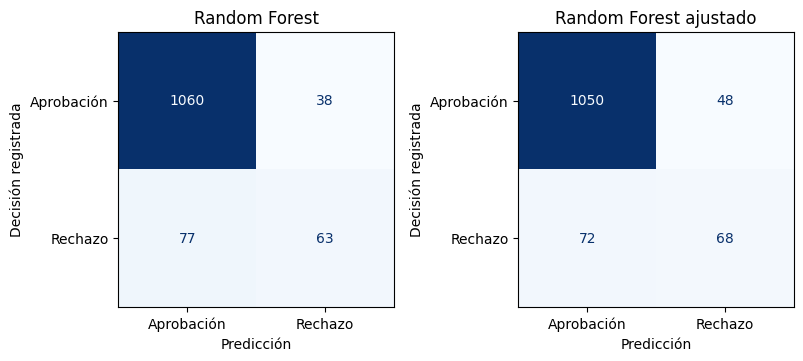

In [44]:
errores_bosques = pd.concat([
    predicciones_cv.loc[predicciones_cv["Modelo"].eq("Random Forest")], predicciones_ajustado,
], ignore_index=True)
recuentos_bosques = pd.DataFrame({
    nombre: confusion_matrix(grupo["Real"], grupo["Prediccion"], labels=[0, 1]).ravel()
    for nombre, grupo in errores_bosques.groupby("Modelo", sort=False)
}, index=["TN", "FP", "FN", "TP"]).T.rename_axis("Modelo")
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), layout="constrained")
for ax, nombre in zip(axes, ["Random Forest", "Random Forest ajustado"]):
    matriz = recuentos_bosques.loc[nombre].to_numpy().reshape(2, 2)
    ConfusionMatrixDisplay(matriz, display_labels=["Aprobación", "Rechazo"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
    )
    ax.set(title=nombre, xlabel="Predicción", ylabel="Decisión registrada")
plt.show()


El ajuste detecta **68 de los 140 rechazos**, frente a 63: reduce los falsos negativos de **77 a 72**, a costa de aumentar los falsos positivos de **38 a 48**. Son cinco rechazos adicionales detectados y diez aprobaciones adicionales señaladas erróneamente. Sin costes reales, este intercambio no demuestra una ventaja económica.


### Selección en desarrollo y registro

Seleccionamos **Random Forest ajustado** por su F1 de desarrollo. El bosque inicial queda a 1,13 puntos y ningún otro candidato entra en la tolerancia de un punto. Guardamos parámetros y resultados; a continuación fijamos el umbral y las condiciones del cierre antes de evaluar test.


In [45]:
nombre_elegido_desarrollo = "Random Forest ajustado"
candidatos_cierre = {**candidatos, "Random Forest ajustado": bosque_ajustado}
modelo_elegido_desarrollo = clone(candidatos_cierre[nombre_elegido_desarrollo])
resultados_busqueda.to_csv(REPORTS / "busqueda_random_forest.csv", index=False)
folds_ajustado.to_csv(REPORTS / "bosque_ajustado_por_fold.csv", index=False)
comparacion_desarrollo.to_csv(REPORTS / "comparacion_desarrollo.csv")
diferencias_bosque.to_csv(REPORTS / "diferencias_bosque_ajustado.csv")
recuentos_bosques.to_csv(REPORTS / "errores_bosques_desarrollo.csv")
predicciones_ajustado.to_csv(REPORTS / "predicciones_cv_bosque_ajustado.csv", index=False)
registro_busqueda = {
    "evaluacion": "../evaluacion/configuracion.json", "preparacion": "configuracion_preparaciones.json",
    "rejilla": rejilla_bosque, "configuraciones": len(resultados_busqueda),
    "folds": len(particiones), "ajustes_busqueda": len(resultados_busqueda) * len(particiones),
    "parametros_fijos": {"n_estimators": 100, "random_state": 42},
    "umbral": UMBRAL, "regla_prediccion": "Puntuacion_1 >= umbral",
    "metrica": "F1 medio no ponderado de validación, clase positiva 1",
    "criterio_seleccion": "Dentro de 0,01 del máximo F1, menor dispersión muestral y después mayor F1",
    "parametros_maximo_f1": busqueda.best_params_, "maximo_f1": float(maximo_f1),
    "parametros_elegidos": parametros_elegidos,
    "parametros_completos_elegidos": bosque_ajustado.named_steps["modelo"].get_params(deep=False),
    "f1_elegido": float(comparacion_desarrollo.loc["Random Forest ajustado", "F1"]),
    "modelo_propuesto": nombre_elegido_desarrollo,
    "grid_search_ejecutado": True, "reajuste_final": False, "test_evaluado": False,
}
(REPORTS / "configuracion_busqueda.json").write_text(
    json.dumps(registro_busqueda, ensure_ascii=False, indent=2) + "\n", encoding="utf-8",
)
print(f"Propuesta de desarrollo: {nombre_elegido_desarrollo}. Test sin evaluar.")


Propuesta de desarrollo: Random Forest ajustado. Test sin evaluar.


### Decisiones fijadas antes de test

Cerramos la búsqueda con **Random Forest ajustado, 100 árboles y umbral 0,5**. Conservamos este umbral común para evaluar el procedimiento desarrollado; no se han establecido costes reales o una capacidad de revisión que justifiquen otro punto de operación. No se afirma que 0,5 sea el óptimo económico ni una probabilidad de impago calibrada.

Los otros tres modelos serán comparadores. Fijamos también tres escenarios hipotéticos de coste y la regla de cinco ejemplos antes de calcular las predicciones de test. Ningún resultado final cambiará la selección.

In [46]:
NOMBRE_FINAL = nombre_elegido_desarrollo
UMBRAL_FINAL = UMBRAL
escenarios_coste = pd.DataFrame([
    {"Escenario": "Igual coste", "Coste_FP": 100, "Coste_FN": 100},
    {"Escenario": "FN cinco veces", "Coste_FP": 100, "Coste_FN": 500},
    {"Escenario": "FN diez veces", "Coste_FP": 100, "Coste_FN": 1000},
]).set_index("Escenario")
# Primeras cinco posiciones del reparto guardado, sin escoger por acierto o etiqueta.
ids_ejemplos = X_test.index[:5]
registro_cierre = {
    "fijado_antes_de_test_utc": datetime.now(timezone.utc).isoformat(),
    "modelo_principal": NOMBRE_FINAL, "umbral": UMBRAL_FINAL,
    "clase_positiva": 1, "regla": "Puntuacion_1 >= umbral",
    "preparacion": "Actual: sin recortes, sin logaritmo y conservando CHILDREN",
    "parametros": {nombre: candidatos_cierre[nombre].named_steps["modelo"].get_params(deep=False)
                   for nombre in orden_cierre},
    "columnas_entrada": list(X_dev.columns),
    "filas_desarrollo": len(X_dev), "filas_test": len(X_test),
    "sha256_particiones": sha256(ruta_particiones.read_bytes()).hexdigest(),
    "sha256_fuentes": configuracion["sha256_fuentes"],
    "sha256_preparacion": sha256((RAIZ / "src/preparacion.py").read_bytes()).hexdigest(),
    "escenarios_euros_hipoteticos": escenarios_coste.reset_index().to_dict("records"),
    "ejemplos": "Primeras cinco posiciones de test, sin seleccionar por etiqueta o acierto",
    "versiones": {lib: version(lib) for lib in ["scikit-learn", "pandas", "numpy", "joblib"]},
    "alcance": "Evaluación interna del conjunto conocido; no validación externa",
    "regla_cierre": "No cambiar modelo, preparación, hiperparámetros o umbral por los resultados de test",
}
(REPORTS / "decisiones_pretest.json").write_text(
    json.dumps(registro_cierre, ensure_ascii=False, indent=2) + "\n", encoding="utf-8",
)
print(f"Fijado: {NOMBRE_FINAL}; umbral {UMBRAL_FINAL}; cuatro candidatos y el mismo test.")


Fijado: Random Forest ajustado; umbral 0.5; cuatro candidatos y el mismo test.


### Reajuste con todo desarrollo

Entrenamos una copia nueva de cada pipeline con los **1.238 clientes de desarrollo**. También se vuelven a aprender las medianas y la codificación con esa muestra; los 310 clientes de test quedan fuera del ajuste.

In [47]:
modelos_finales = {
    nombre: clone(candidatos_cierre[nombre]).fit(X_dev, y_dev)
    for nombre in orden_cierre
}
modelo_final = modelos_finales[NOMBRE_FINAL]
assert X_dev.index.intersection(X_test.index).empty
print(f"{len(modelos_finales)} pipelines reajustados con {len(X_dev)} clientes cada uno. Test sin usar en el ajuste.")


4 pipelines reajustados con 1238 clientes cada uno. Test sin usar en el ajuste.


### Qué entradas utiliza el bosque elegido

Mostramos las diez entradas con mayor importancia por reducción de impureza en el bosque entrenado. Es una descripción del ajuste, no un efecto causal ni una explicación de cada rechazo; puede favorecer variables con muchos valores y repartir importancia entre entradas correlacionadas.

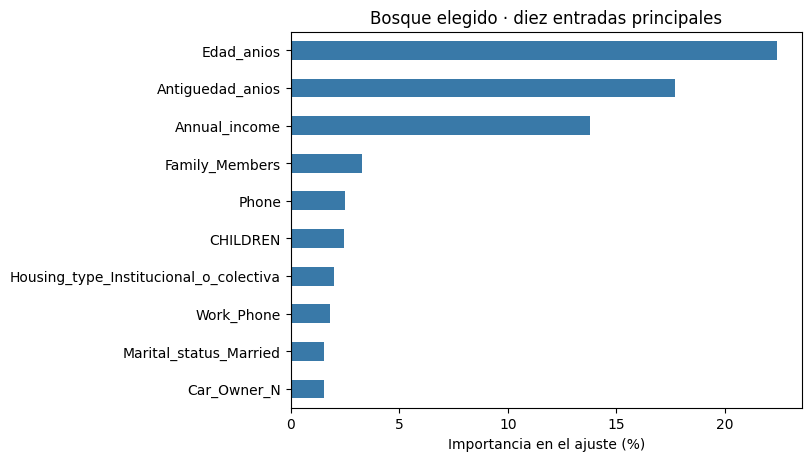

In [48]:
columnas_finales = modelo_final.named_steps["preparar"].named_steps["columnas"].get_feature_names_out()
importancias_finales = pd.Series(
    modelo_final.named_steps["modelo"].feature_importances_,
    index=columnas_finales, name="Importancia",
).sort_values(ascending=False).rename_axis("Entrada")
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
(100 * importancias_finales.head(10).sort_values()).plot.barh(ax=ax, color="#3979a8")
ax.set(xlabel="Importancia en el ajuste (%)", ylabel="", title="Bosque elegido · diez entradas principales")
plt.show()


Edad, antigüedad e ingreso concentran **22,42 %, 17,68 % y 13,79 %** de esta importancia, respectivamente. No indican si aumentar una variable provoca un rechazo. El bosque ofrece un diagnóstico global, pero no la explicación individual necesaria para justificar una decisión de crédito; se mantiene como modelo de análisis.

### Evaluación final en test

Calculamos las mismas cinco métricas para los cuatro modelos, con **rechazo registrado como clase positiva** y umbral 0,5. ROC-AUC utiliza las puntuaciones, no las decisiones 0/1. La tabla mantiene el orden de candidatos: no se vuelve a elegir el modelo por el resultado de test.

In [49]:
filas_test, salidas_test = [], []
for nombre, modelo in modelos_finales.items():
    positiva = list(modelo.classes_).index(1)
    puntuacion = modelo.predict_proba(X_test)[:, positiva]
    prediccion = clasificar_puntuaciones(puntuacion, UMBRAL_FINAL)
    filas_test.append({
        "Modelo": nombre, "F1": f1_score(y_test, prediccion, zero_division=0),
        "Precision": precision_score(y_test, prediccion, zero_division=0),
        "Recall": recall_score(y_test, prediccion, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, puntuacion),
        "Accuracy": accuracy_score(y_test, prediccion),
    })
    salidas_test.append(pd.DataFrame({
        "Ind_ID": X_test.index, "Modelo": nombre, "Real": y_test.to_numpy(),
        "Puntuacion_1": puntuacion, "Prediccion": prediccion,
    }))
metricas_test = pd.DataFrame(filas_test).set_index("Modelo")
predicciones_test = pd.concat(salidas_test, ignore_index=True)
prediccion_final = predicciones_test.loc[predicciones_test["Modelo"].eq(NOMBRE_FINAL)].set_index("Ind_ID")
print(f"Test: {len(y_test)} clientes; {int(y_test.sum())} rechazos registrados. Principal fijado: {NOMBRE_FINAL}.")
display((100 * metricas_test[metricas_tabla]).rename(columns={
    **nombres_metricas, "F1": "F1 test (%)",
}).round(2))


Test: 310 clientes; 35 rechazos registrados. Principal fijado: Random Forest ajustado.


,F1 test (%),Precisión (%),Recall (%),ROC-AUC (%),Accuracy (%)
Modelo,,,,,
Logística,26.28,17.65,51.43,68.70,67.42
Árbol,25.86,18.52,42.86,64.97,72.26
Random Forest,61.02,75.00,51.43,84.88,92.58
Random Forest ajustado,54.84,62.96,48.57,86.05,90.97


El bosque elegido obtiene **F1 54,84 %, recall 48,57 % y AUC 86,05 %**. El bosque inicial alcanza F1 61,02 %: la pequeña ventaja de F1 del ajustado en desarrollo **no se confirma en test**, aunque su AUC es mayor. Conservamos la selección previa para evaluar el procedimiento y comunicamos este resultado; no usamos la tabla final para volver a elegir modelo o umbral.


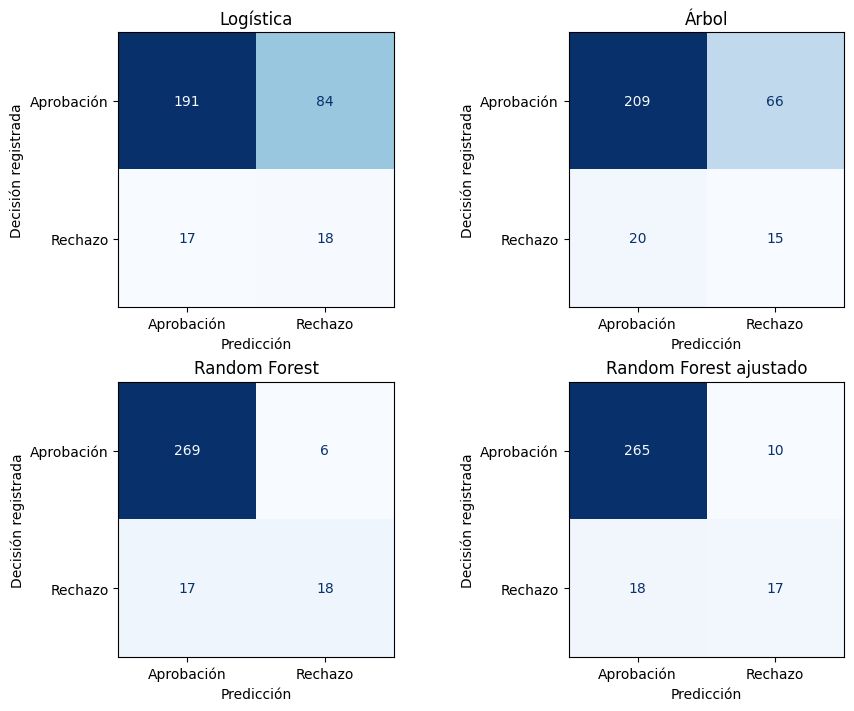

In [50]:
errores_test = pd.DataFrame({
    nombre: confusion_matrix(grupo["Real"], grupo["Prediccion"], labels=[0, 1]).ravel()
    for nombre, grupo in predicciones_test.groupby("Modelo", sort=False)
}, index=["TN", "FP", "FN", "TP"]).T.rename_axis("Modelo")
fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")
for ax, nombre in zip(axes.flat, orden_cierre):
    ConfusionMatrixDisplay(
        errores_test.loc[nombre].to_numpy().reshape(2, 2),
        display_labels=["Aprobación", "Rechazo"],
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set(title=nombre, xlabel="Predicción", ylabel="Decisión registrada")
plt.show()


### Escenarios económicos hipotéticos

Traducimos los errores de las matrices anteriores a tres escenarios: **coste = FP × coste_FP + FN × coste_FN**. FP representa una aprobación histórica clasificada como rechazo; FN, un rechazo histórico clasificado como aprobación. Asignamos 100 € a un falso rechazo y 100, 500 o 1.000 € a un rechazo omitido. Son importes inventados para ilustrar sensibilidad: no son pérdidas, ahorros ni rentabilidad observados y no cambian el modelo elegido.

In [51]:
costes_test = pd.DataFrame({
    nombre: escenarios_coste["Coste_FP"] * errores_test.at[nombre, "FP"]
            + escenarios_coste["Coste_FN"] * errores_test.at[nombre, "FN"]
    for nombre in orden_cierre
})
print("Coste total hipotético en euros para los 310 clientes de test; no extrapolado.")
display(costes_test)


Coste total hipotético en euros para los 310 clientes de test; no extrapolado.


,Logística,Árbol,Random Forest,Random Forest ajustado
Escenario,,,,
Igual coste,10100,8600,2300,2800
FN cinco veces,16900,16600,9100,10000
FN diez veces,25400,26600,17600,19000


El coste hipotético del elegido es **2.800, 10.000 o 19.000 €**, según el escenario. El bosque inicial da un coste menor en los tres porque comete menos FP y FN en este test. Esto no demuestra rentabilidad bancaria ni permite seleccionar de nuevo con la muestra final.

### Cinco ejemplos del modelo final

Tomamos las primeras cinco posiciones del reparto de test, fijadas antes de conocer las predicciones. Mostramos algunos atributos junto a la decisión histórica, la puntuación y la clasificación ya calculadas. No se seleccionan aciertos ni se presentan las puntuaciones como probabilidades de impago.

In [52]:
ejemplos_test = X_test.loc[ids_ejemplos, ["Annual_income", "CHILDREN", "Family_Members", "EDUCATION"]].copy()
ejemplos_test = ejemplos_test.join(prediccion_final[["Real", "Puntuacion_1", "Prediccion"]])
ejemplos_test = ejemplos_test.reset_index(drop=True).rename_axis("Ejemplo")
ejemplos_test.index += 1
ejemplos_test["Acierto"] = ejemplos_test["Real"].eq(ejemplos_test["Prediccion"])
display(ejemplos_test.rename(columns={
    "Annual_income": "Ingreso anual", "CHILDREN": "Hijos", "Family_Members": "Familia",
    "EDUCATION": "Educación", "Real": "Etiqueta (0/1)", "Puntuacion_1": "Puntuación rechazo",
    "Prediccion": "Predicción (0/1)",
}).round(3))


,Ingreso anual,Hijos,Familia,Educación,Etiqueta (0/1),Puntuación rechazo,Predicción (0/1),Acierto
Ejemplo,,,,,,,,
1,180000.0,2,4,Higher education,0,0.040,0,True
2,211500.0,0,2,Secondary / secondary special,0,0.150,0,True
3,225000.0,0,1,Higher education,0,0.176,0,True
4,112500.0,0,2,Secondary / secondary special,0,0.050,0,True
5,180000.0,0,2,Secondary / secondary special,0,0.010,0,True


Los cinco ejemplos son aprobaciones históricas y se clasifican como tales. Ilustran la salida del pipeline; las matrices anteriores muestran todos los errores.

### Conclusiones y uso del resultado

- **Random Forest ajustado**, seleccionado en desarrollo, obtiene F1 **54,84 %** en test. El bosque inicial alcanza **61,02 %**: el ajuste no confirma la mejora esperada.
- El elegido detecta **17 de 35 rechazos**, omite 18 y genera 10 falsos rechazos. Un caso cambia el recall en **2,86 puntos**; la accuracy de **90,97 %** no compensa esa detección limitada.
- La evaluación es **interna y sobre decisiones históricas**. Faltan fechas, explicación de la etiqueta, costes reales y validación externa. Las importancias no explican rechazos individuales ni acreditan equidad.
- Se entrega un **análisis reproducible**, sin recomendar decisiones automáticas de crédito. Investigar mejoras requeriría evidencia independiente; este test ya no sirve como muestra desconocida.

### Guardado de resultados y modelo

Guardamos las tablas, las predicciones y la configuración de cierre, junto con el pipeline entrenado y su umbral. Esta celda conserva resultados ya calculados; no vuelve a entrenar ni a evaluar modelos.


In [53]:
metricas_test.to_csv(REPORTS / "metricas_test.csv")
errores_test.to_csv(REPORTS / "errores_test.csv")
importancias_finales.to_csv(REPORTS / "importancias_bosque_final.csv")
scenarios = escenarios_coste.join(costes_test)
scenarios.to_csv(REPORTS / "costes_hipoteticos_test.csv")
# Predicciones individuales y ejemplos de clientes: evidencias locales excluidas de Git.
predicciones_test.to_csv(REPORTS / "predicciones_test.csv", index=False)
ejemplos_test.to_csv(REPORTS / "casos_test.csv")
MODELOS = RAIZ / "models"
MODELOS.mkdir(exist_ok=True)
joblib.dump({
    "modelo": modelo_final, "umbral": UMBRAL_FINAL, "clase_positiva": 1,
    "columnas_entrada": list(X_dev.columns), "modelo_principal": NOMBRE_FINAL,
}, MODELOS / "clasificador-solicitudes.joblib")
registro_final = {
    **registro_cierre, "evaluado_utc": datetime.now(timezone.utc).isoformat(),
    "reajuste_final": True, "test_evaluado": True,
    "metricas_test": metricas_test.reset_index().to_dict("records"),
    "errores_test": errores_test.reset_index().to_dict("records"),
    "artefacto_local": "../models/clasificador-solicitudes.joblib",
    "decision_entrega": "Proyecto analítico de portfolio; no recomendado para concesión automática",
}
(REPORTS / "evaluacion_final.json").write_text(
    json.dumps(registro_final, ensure_ascii=False, indent=2) + "\n", encoding="utf-8",
)
print("Evaluación y configuración guardadas. Modelo final local; sin reajustar con test.")


Evaluación y configuración guardadas. Modelo final local; sin reajustar con test.


El recorrido analítico queda cerrado con las decisiones y limitaciones anteriores. Los [informes](../reports/README.md) conservan las evidencias del análisis. El [modelo local](../models/README.md) reúne preparación y clasificador para reproducir las predicciones. Una nueva investigación requeriría otra evaluación independiente; no se reutilizará este test para justificar mejoras.